Install pymysql untuk melakukan koneksi dengan database

In [ ]:
!pip install pymysql

Import Libarary yang dibutuhkan

In [ ]:
# Import Library


import pymysql
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
import statsmodels.formula.api as smf


ACCENT  = "#C0392B"   # hari JSM
NEUTRAL = "#A6A6A6"   # pembanding

# 1. Data Collection

Setup Connection to cloud Database

In [ ]:
# Create Connection
connection = pymysql.connect(
    host='vmlp.pwdlearning.cloud',
    user = 'student_ds',
    password= '@studentDS#2026',
    database= 'alfamart',
)

Select Query utnuk mengambil table yang dibutuhkan di database

In [ ]:
# Select Query for every tables
query_alfa_complaint_tickets = "select * from alfa_complaint_tickets"
query_alfa_members = 'select * from alfa_members'
query_alfa_pos_transactions = 'select * from alfa_pos_transactions'
query_alfa_products = 'select * from alfa_products'
query_alfa_stores = 'select * from alfa_stores'

Mengimport data dari Cloud Database

In [ ]:
# MySql Databas to dataFrame format
orig_alfa_complaint_tickets = pd.read_sql_query(query_alfa_complaint_tickets, con=connection)
orig_alfa_members = pd.read_sql_query(query_alfa_members, con=connection)
orig_alfa_pos_transactions = pd.read_sql_query(query_alfa_pos_transactions, con=connection)
orig_alfa_products = pd.read_sql_query(query_alfa_products, con=connection)
orig_alfa_stores = pd.read_sql_query(query_alfa_stores, con=connection)

/tmp/ipykernel_1005/2644056071.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  orig_alfa_complaint_tickets = pd.read_sql_query(query_alfa_complaint_tickets, con=connection)
/tmp/ipykernel_1005/2644056071.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  orig_alfa_members = pd.read_sql_query(query_alfa_members, con=connection)
/tmp/ipykernel_1005/2644056071.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  orig_alfa_pos_transactions = pd.read_sql_query(query_alfa_pos_transactions, con=connection)
/tmp/ipykernel_1005/

Membuat salinan data untuk diolah

In [ ]:
alfa_complaint_tickets = orig_alfa_complaint_tickets.copy()
alfa_members = orig_alfa_members.copy()
alfa_pos_transactions = orig_alfa_pos_transactions.copy()
alfa_products = orig_alfa_products.copy()
alfa_stores = orig_alfa_stores.copy()

Menampilkan bentuk metrik dari semua table

In [ ]:
# check collected data

display(
    orig_alfa_pos_transactions.shape,
    orig_alfa_stores.shape,
    orig_alfa_products.shape,
    orig_alfa_members.shape,
    orig_alfa_complaint_tickets.shape
)

(455148, 12)

(1003, 10)

(507, 11)

(48214, 10)

(10759, 9)

Menampilkan top 5 data dari setiap table

In [ ]:
# cek data
display(
    alfa_complaint_tickets.head(),
    alfa_members.head(),
    alfa_pos_transactions.head(),
    alfa_products.head(),
    alfa_stores.head()
)

,ticket_id,receipt_id,complaint_category,ticket_date,channel,resolution_status,resolution_time_hours,csat_score,disputed_amount
0,TCK0100000,RCP00263916,Produk Kadaluarsa/Rusak,2020-11-15 14:00:00,Langsung ke Gerai,Resolved,37.2,4.0,78287.0
1,TCK0100001,RCP00105974,Produk Kadaluarsa/Rusak,2020-12-08 22:00:00,Media Sosial,Escalated,64.0,1.0,9115.0
2,TCK0100002,RCP00148221,Antrian Lama,2020-12-08 20:00:00,Aplikasi Alfagift,Escalated,56.7,3.0,10974.0
3,TCK0100003,RCP00284125,Produk Kadaluarsa/Rusak,2020-12-12 11:00:00,Langsung ke Gerai,Resolved,19.6,3.0,119691.0
4,TCK0100004,RCP00229184,Produk Kadaluarsa/Rusak,2020-12-16 18:00:00,Call Center 1500-959,Resolved,14.9,5.0,20264.0


,member_id,registration_date,home_city,gender,birth_year,membership_tier,acquisition_channel,phone_verified,points_balance,last_active_date
0,MEM-00001,2022-02-28,Tangerang,P,1981,Reguler,Aplikasi Alfagift,1,20685,2023-08-22
1,MEM-00002,2022-03-14,Bandung,L,1995,Reguler,Daftar di Toko,0,23505,2023-08-14
2,MEM-00003,2021-06-15,Depok,P,1988,Reguler,Aplikasi Alfagift,1,12672,2022-01-13
3,MEM-00004,2021-09-17,Tangerang,L,2003,Reguler,Website,0,46417,2024-01-18
4,MEM-00005,2022-02-14,Bogor,P,1992,Reguler,Daftar di Toko,1,3473,2023-05-20


,receipt_id,store_id,sku_id,member_id,trx_time,payment_method,qty,total_price,transaction_status,discount_amount,points_earned,checkout_channel
0,RCP00000001,SAT-0142,SKU000180,MEM-11847,2022-12-24 21:00:00,BCA Debit,1,33500.0,COMPLETED,0.0,3,Kasir Reguler
1,RCP00000002,SAT-0294,SKU000115,None,2022-10-25 14:00:00,Cash,2,62200.0,VOID,0.0,0,Kasir Reguler
2,RCP00000003,SAT-0623,SKU000132,None,2022-12-02 08:00:00,Tunai,3,85500.0,COMPLETED,0.0,0,Kasir Reguler
3,RCP00000004,SAT-0386,SKU000262,MEM-44261,2024-07-28 09:00:00,CASH,12,191784.0,COMPLETED,122616.0,19,Kasir Reguler
4,RCP00000005,SAT-0665,SKU000437,MEM-48359,2023-07-14 12:00:00,ShopeePay,1,12692.0,COMPLETED,4008.0,1,Kasir Reguler


,sku_id,product_name,category,brand,unit_price,unit_of_measure,is_perishable,shelf_life_days,supplier_id,is_jsm_promo,jsm_discount_pct
0,SKU000001,Air Mineral Aqua,Beverage,Danone-Aqua,12100.0,botol,0,641.0,SUP-107,1,0.31
1,SKU000002,Indm Grg,Food & Staples,Indofood,39000.0,pack,0,502.0,SUP-184,1,0.34
2,SKU000003,Bimoli Pouch 2000ml,Food & Staples,Salim Ivomas,12900.0,pack,0,599.0,SUP-162,0,0.00
3,SKU000004,Air Mineral Aqua,Beverage,Danone-Aqua,27800.0,botol,0,708.0,SUP-132,0,0.00
4,SKU000005,Rokok Sampoerna Mild,Cigarettes,Sampoerna,13800.0,pack,0,NaN,SUP-183,0,0.00


,store_id,store_name,city,province,open_date,store_type,store_format,store_size_sqm,has_self_checkout,region_code
0,SAT-0001,Alfamart Sudirman 0,Depok,Jawa Barat,2022-05-08,Perkantoran,Sedang (Reguler),147,0,REG-JABAR-3
1,SAT-0002,Alfamart Diponegoro 1,Surabaya,Jawa Timur,2022-09-16,Residential/Perumahan,Sedang (Reguler),206,0,REG-JATIM-4
2,SAT-0003,Alfamart Melati 2,Depok,Jawa Barat,2022-05-24,Perkantoran,Sedang (Reguler),203,0,REG-JABAR-1
3,SAT-0004,Alfamart Sudirman 3,Tangerang,Banten,2022-05-01,Residential/Perumahan,Besar (Reguler Plus),359,0,REG-BANTEN-4
4,SAT-0005,Alfamart Melati 4,Bogor,Jawa Barat,2021-03-27,Residential/Perumahan,Kecil (Express),69,0,REG-JABAR-1


Export data to CSV, sehingga tidak perlu ke cloud database lagi

In [ ]:
# Export Data Raw
alfa_complaint_tickets.to_csv('alfa_complaint_tickets_raw.csv', index=False)
alfa_members.to_csv('alfa_members_raw.csv', index=False)
alfa_pos_transactions.to_csv('alfa_pos_transactions_raw.csv', index=False)
alfa_products.to_csv('alfa_products_raw.csv', index=False)
alfa_stores.to_csv('alfa_stores_raw.csv', index=False)

# 2. Data Exploration

2.1 Melihat informasi dasar dari setiap table yang ada

In [ ]:
# NaN checking, tipe per kolom

alfa_complaint_tickets.info(),
alfa_members.info(),
alfa_pos_transactions.info(),
alfa_products.info(),
alfa_stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10759 entries, 0 to 10758
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   ticket_id              10759 non-null  object        
 1   receipt_id             10759 non-null  object        
 2   complaint_category     10759 non-null  object        
 3   ticket_date            10759 non-null  datetime64[ns]
 4   channel                10759 non-null  object        
 5   resolution_status      10759 non-null  object        
 6   resolution_time_hours  9273 non-null   float64       
 7   csat_score             9273 non-null   float64       
 8   disputed_amount        10759 non-null  float64       
dtypes: datetime64[ns](1), float64(3), object(5)
memory usage: 756.6+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48214 entries, 0 to 48213
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------ 

Temuan kolom kotor:
- Terdapat data null pada resolution_time_hours, csat_store pada Complaint_Ticket

2.2 Cek Duplicate

In [ ]:
# Check Duplicate

display(
    alfa_complaint_tickets.duplicated().sum(),
    alfa_members.duplicated().sum(),
    alfa_pos_transactions.duplicated().sum(),
    alfa_products.duplicated().sum(),
    alfa_stores.duplicated().sum()
)

np.int64(0)

np.int64(0)

np.int64(0)

np.int64(0)

np.int64(0)

TIdak terdapat kolom duplikat

2.3 Cek semua jenis ID valid. ada di tabel sumber dimensi (tidak ada ID yang stray)

In [ ]:
display(
    (~alfa_pos_transactions["sku_id"].isin(alfa_products["sku_id"])).sum(),
    (~alfa_pos_transactions["store_id"].isin(alfa_stores["store_id"])).sum(),
    (~alfa_pos_transactions["member_id"].dropna().isin(alfa_members["member_id"])).sum(),
    (~alfa_complaint_tickets["receipt_id"].isin(alfa_pos_transactions["receipt_id"])).sum()
)
# finding: semua foreign key valid.

np.int64(0)

np.int64(0)

np.int64(0)

np.int64(0)

Semua foreign key valid

2.4 Cek variasi penulisan

In [ ]:
display(
    alfa_pos_transactions["payment_method"].value_counts(),
    alfa_pos_transactions["transaction_status"].value_counts(),
    alfa_pos_transactions["checkout_channel"].value_counts(),
    alfa_complaint_tickets["complaint_category"].value_counts(),
    alfa_complaint_tickets["resolution_status"].value_counts(),
    alfa_members["membership_tier"].value_counts(),
    alfa_members["acquisition_channel"].value_counts(),
    alfa_products["product_name"].value_counts(),
    alfa_products["category"].value_counts(),
    alfa_products["unit_of_measure"].value_counts(),
    alfa_products["is_jsm_promo"].value_counts(),
    alfa_stores["store_type"].value_counts(),
    alfa_stores["store_format"].value_counts()
)

# finding: penulisan payment_method & product name perlu di standarisasi.
# kolom transaction_status ada 14K void
# kolom lain aman.

,count
payment_method,
Cash,90496
CASH,60523
BCA Debit,45779
Gopay,45704
Tunai,45664
ShopeePay,45224
qris,30593
OVO,30488
debit bca,30373


,count
transaction_status,
COMPLETED,441124
VOID,14024


,count
checkout_channel,
Kasir Reguler,430438
Self-Checkout Mandiri,24710


,count
complaint_category,
Pelayanan Kasir,3156
Produk Kadaluarsa/Rusak,2899
Antrian Lama,2591
Ketersediaan Stok,1993
Harga Tidak Sesuai Struk,78
Kembalian Kurang,42


,count
resolution_status,
Resolved,7664
Escalated,1609
Pending,1486


...

,count
category,
Food & Staples,205
Cigarettes,105
Personal Care,101
Beverage,96


,count
unit_of_measure,
pack,310
pcs,101
botol,96


,count
is_jsm_promo,
0,413
1,94


,count
store_type,
Residential/Perumahan,761
Perkantoran,163
Dekat Pasar/Grosir,79


,count
store_format,
Sedang (Reguler),626
Kecil (Express),235
Besar (Reguler Plus),142


2.5 Cek statistik deskriptif

In [ ]:
# Check Data by Describe
display(
    alfa_complaint_tickets.describe(),
    alfa_members.describe(),
    alfa_pos_transactions.describe(),
    alfa_products.describe(),
    alfa_stores.describe()
)

,ticket_date,resolution_time_hours,csat_score,disputed_amount
count,10759,9273.000000,9273.000000,1.075900e+04
mean,2023-06-08 12:40:56.994144512,27.037216,3.877925,5.518030e+05
min,2020-11-15 14:00:00,0.200000,1.000000,3.560000e+02
25%,2022-09-18 06:30:00,10.800000,3.000000,9.955500e+03
50%,2023-06-11 12:00:00,19.700000,4.000000,2.287700e+04
75%,2024-02-17 19:30:00,34.500000,5.000000,5.653950e+04
max,2025-10-14 10:00:00,255.300000,5.000000,2.507606e+08
std,NaN,24.415805,1.255180,7.054200e+06


,birth_year,phone_verified,points_balance
count,48214.000000,48214.000000,48214.000000
mean,1985.419360,0.822666,25045.357531
std,12.125407,0.381955,14431.802111
min,1965.000000,0.000000,2.000000
25%,1975.000000,1.000000,12495.500000
50%,1985.000000,1.000000,25178.000000
75%,1996.000000,1.000000,37548.000000
max,2006.000000,1.000000,49999.000000


,trx_time,qty,total_price,discount_amount,points_earned
count,455148,455148.000000,4.551480e+05,4.551480e+05,455148.000000
mean,2023-06-09 06:48:44.812148992,16.060624,3.655186e+05,2.382300e+04,27.498317
min,2020-10-01 16:00:00,-7.000000,-3.129000e+05,-1.048040e+05,0.000000
25%,2022-09-15 00:00:00,1.000000,2.340800e+04,0.000000e+00,0.000000
50%,2023-06-07 11:00:00,2.000000,4.240000e+04,0.000000e+00,2.000000
75%,2024-02-26 09:00:00,4.000000,1.005000e+05,0.000000e+00,7.000000
max,2025-11-15 00:00:00,9992.000000,4.402944e+08,1.495703e+08,64862.000000
std,NaN,238.285278,6.256414e+06,5.894629e+05,590.217173


,unit_price,is_perishable,shelf_life_days,is_jsm_promo,jsm_discount_pct
count,507.000000,507.000000,402.000000,507.000000,507.000000
mean,24473.767258,0.047337,440.477612,0.185404,0.052544
std,11953.852398,0.212569,179.791056,0.389009,0.113967
min,3200.000000,0.000000,30.000000,0.000000,0.000000
25%,15100.000000,0.000000,302.000000,0.000000,0.000000
50%,24000.000000,0.000000,459.500000,0.000000,0.000000
75%,34600.000000,0.000000,589.750000,0.000000,0.000000
max,44800.000000,1.000000,729.000000,1.000000,0.400000


,store_size_sqm,has_self_checkout
count,1003.000000,1003.000000
mean,169.822532,0.179462
std,70.643820,0.383930
min,60.000000,0.000000
25%,122.500000,0.000000
50%,165.000000,0.000000
75%,201.000000,0.000000
max,399.000000,1.000000


List data cleaning Follow-Up:

- penulisan payment_method perlu standard
- penulisan product name perlu di standarisasi.
- kolom transaction_status ada 14K void perlu di exclude.
- pos_trans-qty ada negative value (<-7)
- pos_trans-qty ada nilai extreme 100-9999
- pos_trans-total price ada negative value -3.12e5
- pos_trans-discount amount ada negative value -1.04e5



# 3. Data Cleaning

In [ ]:
# Prepare gabungan dataset untuk proses cleaning: raw

raw = alfa_pos_transactions.merge(alfa_products, on="sku_id", how="left")
raw = raw.merge(alfa_stores, on="store_id", how="left")
raw = raw.merge(alfa_members, on="member_id", how="left")
raw["trx_time"]  = pd.to_datetime(raw["trx_time"])
raw["open_date"] = pd.to_datetime(raw["open_date"])
raw["is_jsm_day"] = raw["trx_time"].dt.dayofweek >= 4
N_RAW = len(raw)
N_RAW             # masih utuh: 455,148

455148

Terdapat 455148 row data setelah dilakukan merge

## Anomali 1: Payment_method inkonsistensi penulisan

In [ ]:
payment_map = {"Cash": "Tunai", "CASH": "Tunai", "Tunai": "Tunai",
               "BCA Debit": "Debit BCA", "debit bca": "Debit BCA",
               "QRIS": "QRIS", "qris": "QRIS",
               "Gopay": "GoPay", "OVO": "OVO", "ShopeePay": "ShopeePay"}
raw["payment_method"] = raw["payment_method"].map(payment_map)
display(raw["payment_method"].value_counts())

,count
payment_method,
Tunai,196683
Debit BCA,76152
QRIS,60897
GoPay,45704
ShopeePay,45224
OVO,30488


## Anomali 2 : product_name inkonsistensi penulisan

In [ ]:
# Cek data unik semua nama product

display(
    alfa_products["sku_id"].nunique(),
    alfa_products["product_name"].nunique(),
    alfa_products["product_name"].value_counts()
)

507

20

,count
product_name,
Pepsodent 190g,55
ROKOK SAMPOERNA MILD,54
Rokok Sampoerna Mild,50
PEPSODENT 190G,45
Mnyk Goreng Bimoli,44
Air Mineral Aqua,40
Indm Grg,36
Bimoli Pouch 2000ml,35
Aqua 600ml,33


In [ ]:
# Penanganan Anomali 2:standarisasi
product_map = {
    "Air Mineral Aqua": "Aqua 600ml",          "AQ btl 600": "Aqua 600ml",
    "Indm Grg": "Indomie Goreng",              "INDOMIE MIE GORENG": "Indomie Goreng",
    "Bimoli Pouch 2000ml": "Minyak Bimoli 2L", "Mnyk Goreng Bimoli": "Minyak Bimoli 2L",
    "PEPSODENT 190G": "Pepsodent 190g",
    "ROKOK SAMPOERNA MILD": "Rokok Sampoerna Mild",
}
alfa_products["product_name"] = alfa_products["product_name"].replace(product_map)
raw["product_name"] = raw["product_name"].replace(product_map)
display(alfa_products["product_name"].nunique(), alfa_products.groupby("product_name")["brand"].nunique().max())

12

1

## Anomali 3: Cek transaction_status = VOID


Kolom & jenis: transaction_status bernilai VOID (transaksi dibatalkan).
Aturan dilanggar: transaksi VOID tidak menghasilkan penjualan maupun diskon riil (logika bisnis).

In [ ]:
# Cek proporsi transaksi VOID: 3% data (14K baris)
display(
    raw["transaction_status"].value_counts(),
    (raw["transaction_status"] == "VOID").mean() * 100
)

,count
transaction_status,
COMPLETED,441124
VOID,14024


np.float64(3.0811955671561777)

In [ ]:
display(
    raw.groupby("checkout_channel")["transaction_status"].apply(lambda x: (x == "VOID").mean() * 100),
    raw.groupby("payment_method")["transaction_status"].apply(lambda x: (x == "VOID").mean() * 100),
    raw.groupby("store_type")["transaction_status"].apply(lambda x: (x == "VOID").mean() * 100),
    raw.groupby("city")["transaction_status"].apply(lambda x: (x == "VOID").mean() * 100),
    raw.groupby("is_jsm_day")["transaction_status"].apply(lambda x: (x == "VOID").mean() * 100),
    raw.groupby(pd.cut(raw["qty"], [-10, 0, 5, 30, 89, 10000]))["transaction_status"].apply(lambda x: (x == "VOID").mean() * 100)
)

# finding: konsentrasi rata sekitar 3% di ragam kondisi, KECUALI di qty transaction 89 ke atas

/tmp/ipykernel_1005/3359338792.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  raw.groupby(pd.cut(raw["qty"], [-10, 0, 5, 30, 89, 10000]))["transaction_status"].apply(lambda x: (x == "VOID").mean() * 100)


,transaction_status
checkout_channel,
Kasir Reguler,3.096149
Self-Checkout Mandiri,2.820720


,transaction_status
payment_method,
Debit BCA,3.038660
GoPay,3.159461
OVO,3.060220
QRIS,2.949242
ShopeePay,3.069167
Tunai,3.126351


,transaction_status
store_type,
Dekat Pasar/Grosir,2.647651
Perkantoran,3.115795
Residential/Perumahan,3.152359


,transaction_status
city,
Bandung,3.239746
Bekasi,3.062916
Bogor,3.110736
Depok,3.093136
Jakarta,2.882146
Malang,3.071912
Medan,3.076146
Semarang,3.091395
Surabaya,3.170494


,transaction_status
is_jsm_day,
False,3.147195
True,3.006519


,transaction_status
qty,
"(-10, 0]",2.292650
"(0, 5]",2.864361
"(5, 30]",2.870039
"(30, 89]",2.055301
"(89, 10000]",79.169413


## Anomali 4: akan ditangani dengan flag (is_void) & dikeluarkan dari analisis penjualan.

karena sebaran merata 3% di semua segmen, kecuali qty >89 (79%).

In [ ]:
# Penanganan Anomali 2: VOID transactions all flag & will be excluded from analysis
raw["is_void"] = raw["transaction_status"] == "VOID"
display(raw["is_void"].sum(), len(raw))      # sebelum = sesudah (baris tidak dihapus, hanya ditandai)

np.int64(14024)

455148

## Anomali 5: member_id kosong

Identifikasi dan analisis apakah ada pola atau persebaran acak?

In [ ]:
display(raw["member_id"].isna().sum(), raw["member_id"].isna().mean() * 100) # ada 33% baris transaksi (receipt) tanpa member_id

# Analisa apakah ada pola atau persebaran acak?
display(
    raw.groupby("payment_method")["member_id"].apply(lambda x: x.isna().mean() * 100),
    raw.groupby("store_type")["member_id"].apply(lambda x: x.isna().mean() * 100),
    raw.groupby("is_jsm_day")["member_id"].apply(lambda x: x.isna().mean() * 100)
)

# finding: persebaran member_id kosong rata di beragam segmen, kecuali saat pembayaran dengan metode: Tunai


np.int64(153646)

np.float64(33.757371228699235)

,member_id
payment_method,
Debit BCA,20.038870
GoPay,18.687642
OVO,21.352663
QRIS,21.664450
ShopeePay,18.799752
Tunai,51.677064


,member_id
store_type,
Dekat Pasar/Grosir,31.078178
Perkantoran,34.186519
Residential/Perumahan,34.150964


,member_id
is_jsm_day,
False,34.266924
True,33.180822


In [ ]:
# Penanganan Anomali 5: flag (is_member). karena masih ada pola di pembayaran tunai dan bisa dipakai untuk analisa lain seperti tujuan promo JSM: akuisisi pelanggan -> menjadi member

raw["is_member"] = raw["member_id"].notna()
raw['member_id'] = raw['member_id'].fillna('Non Member')
display(raw["is_member"].value_counts(), len(raw))

,count
is_member,
True,301502
False,153646


455148

## Anomali 6: qty negatif

Identifikasi: nilai negatif tidak valid secara logika penjualan. qty penjualan harus >= 1
Analisa: apakah tersebar atau terkumpul di segmen tertentu?

In [ ]:
display(
    (raw["qty"] < 0).sum(),
    (raw["qty"] < 0).mean() * 100,                              # qty negative mewakili 0.3% data (sangat kecil)
    raw[raw["qty"] < 0]["qty"].value_counts().sort_index(),
    (raw["qty"] == 0).sum()
)

# Analisa qty negatif
display(
    raw[raw["qty"] < 0]["transaction_status"].value_counts(),   # statusnya bagaimana jika qty negatif? mayoritas completed transaction
    (raw[raw["qty"] < 0]["total_price"] < 0).mean() * 100,      # total ikut negatif? iya, saat qty -, total_price -
    raw[raw["qty"] < 0]["store_type"].value_counts(normalize=True) * 100 # apakah banyak di toko tertentu? 72% di perumahan
)

np.int64(1483)

np.float64(0.3258280822941109)

,count
qty,
-7,221
-6,231
-5,222
-4,199
-3,236
-2,196
-1,178


np.int64(0)

,count
transaction_status,
COMPLETED,1449
VOID,34


np.float64(100.0)

,proportion
store_type,
Residential/Perumahan,72.623061
Perkantoran,19.150371
Dekat Pasar/Grosir,8.226568


In [ ]:
# Penanganan: flag (is_return) & exclude dari analisa (hanya mewakili 0.3% data)
raw["is_return"] = raw["qty"] < 0
display(raw["is_return"].sum(), (raw[~raw["is_return"]]["qty"] < 0).sum())


np.int64(1483)

np.int64(0)

## Anomali 6B: qty ekstrem
Analisa: eksplorasi value dan frekuensi qty tersebut

In [ ]:
pos_qty = raw[(raw["qty"] > 0) & (raw["transaction_status"]=="COMPLETED")]
valid_trx = raw[raw["qty"] > 0].copy()
# print("Persentil Kuantitas non-Negatif:")
# display(pos_qty.quantile([0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999, 0.9999]))

print("=== ANALISIS SEBARAN PERSENTIL KUANTITAS (QTY > 0) ===")
quantiles = [0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999, 0.9999]
for q in quantiles:
    print(f"Persentil {q*100:.2f}%: {pos_qty['qty'].quantile(q):.2f} unit")

# Frekuensi Kemunculan Tiap Nilai Kuantitas
print("\n=== 20 Kuantitas dengan Frekuensi Tertinggi (Global) ===")
df_table = valid_trx['qty'].value_counts().sort_index().reset_index()
df_table.columns = ['Kuantitas', 'Frekuensi']
total_rows = df_table['Frekuensi'].sum()
df_table['% Frekuensi'] = (df_table['Frekuensi'] / total_rows) * 100
df_table['% Kumulatif'] = df_table['% Frekuensi'].cumsum()
df_table['% Frekuensi'] = df_table['% Frekuensi'].map('{:.3f}%'.format)
df_table['% Kumulatif'] = df_table['% Kumulatif'].map('{:.3f}%'.format)
tabel_akhir = df_table.sort_values(by='Frekuensi', ascending=False).head(20).reset_index(drop=True)
print(tabel_akhir)

def get_iqr_upper_bound(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + (1.5 * IQR)
    return upper_bound

# 2. Menghitung batas atas IQR spesifik per produk
# Fungsi transform memastikan batas kewajaran ditempelkan pada setiap baris transaksi
# sesuai dengan nama produknya masing-masing
raw['batas_wajar_qty'] = raw.groupby('product_name')['qty'].transform(
    lambda x: get_iqr_upper_bound(x.dropna())
)

# 3. Mengisolasi transaksi yang terindikasi Outlier (Reseller)
df_reseller = raw[raw['qty'] > raw['batas_wajar_qty']]

# Melihat batas wajar untuk masing-masing produk
df_katalog_batas = raw[['product_name','batas_wajar_qty']].drop_duplicates()
print("\nKatalog Batas Wajar Pembelian per Produk:")
print(df_katalog_batas.sort_values(by='batas_wajar_qty', ascending=False).head(10))

=== ANALISIS SEBARAN PERSENTIL KUANTITAS (QTY > 0) ===
Persentil 50.00%: 2.00 unit
Persentil 75.00%: 4.00 unit
Persentil 90.00%: 12.00 unit
Persentil 95.00%: 25.00 unit
Persentil 99.00%: 77.00 unit
Persentil 99.50%: 84.00 unit
Persentil 99.90%: 89.00 unit
Persentil 99.99%: 6696.80 unit

=== 20 Kuantitas dengan Frekuensi Tertinggi (Global) ===
    Kuantitas  Frekuensi % Frekuensi % Kumulatif
0           1     174008     38.356%     38.356%
1           2      84987     18.733%     57.089%
2           3      56103     12.367%     69.456%
3           5      55495     12.233%     87.429%
4           4      26040      5.740%     75.196%
5          24      15347      3.383%     94.743%
6          12      14870      3.278%     90.706%
7         999        769      0.170%     99.848%
8          65        400      0.088%     97.872%
9          62        371      0.082%     97.635%
10         74        370      0.082%     98.565%
11         39        365      0.080%     95.869%
12         68     

Penanganan: Anomali 6B akan diflag dan tetap diikutkan dalam analisa tanpa exclude. karena angka di atas P95 bisa jadi reseller (yg dicari), dan masih represent 5% data dengan qty >24 (moderate).

## Anomali 7: transaksi terjadi sebelum tanggal gerai buka.

Analisa: apakah terkumpul di store tertentu/type tertentu? apakah selisihnya berpola?

In [ ]:
before_open = raw[raw["trx_time"] < raw["open_date"]]

display(
    (raw["trx_time"] < raw["open_date"]).sum(),
    (raw["trx_time"] < raw["open_date"]).mean() * 100
)
# kondisi ini ditemukan di 9,000 baris (1.9%)

display(
    before_open["store_id"].nunique(),
    (before_open["open_date"] - before_open["trx_time"]).dt.days.describe(),
    before_open["store_type"].value_counts(normalize=True) * 100,
    raw["store_type"].value_counts(normalize=True) * 100
)

# kebanyakan terjadi di store type: residential/perumahan (71%)

np.int64(9000)

np.float64(1.9773787866803765)

1000

,0
count,9000.000000
mean,54.837111
std,26.146635
min,10.000000
25%,32.000000
50%,55.000000
75%,78.000000
max,99.000000


,proportion
store_type,
Residential/Perumahan,76.222222
Perkantoran,16.133333
Dekat Pasar/Grosir,7.644444


,proportion
store_type,
Residential/Perumahan,71.648123
Perkantoran,15.365112
Dekat Pasar/Grosir,12.986765


In [ ]:
# Penanganan: situasi ini tidak bisa dipastikan mana yang salah (tanggal transaksi atau tanggal buka),
# sehingga exclude & flag dipilih
# dampak penanganan ke 9,000 (1.9%) baris analisa. akan diuji ulang di uji sensitivitas.

raw["is_before_open"] = raw["trx_time"] < raw["open_date"]
display(raw["is_before_open"].sum())

np.int64(9000)

## Anomali 8: total_price =/= unit_price x qty
ditemukan beberapa baris dengan perhitungan yang tidak konsisten.

In [ ]:
raw["gross_price"] = raw["unit_price"] * raw["qty"]
display(
    (raw["total_price"] < raw["gross_price"]).sum(),
    pd.crosstab(raw["total_price"] < raw["gross_price"], [raw["is_jsm_day"], raw["is_jsm_promo"]])
)

# apakah selisihnya tepat dengan diskon amount?
display(
    ((raw["total_price"] - (raw["gross_price"] - raw["discount_amount"])).abs() > 1).sum(),
    ((raw["discount_amount"] - raw["gross_price"] * raw["jsm_discount_pct"]).abs() > 1)[raw["discount_amount"] != 0].sum()
)

np.int64(55939)

is_jsm_day     False          True        
is_jsm_promo       0      1       0      1
row_0                                     
False         193854  47758  157493    104
True               0      0       0  55939

np.int64(0)

np.int64(0)

Penanganan: anomali 8 akan dibiarkan. Karena ini bukan error. ketidaksamaan antara total_price dan unit_price x qty menunjukkan 100% selisih persis dari penerapan jsm_discount_pct.

## Anomali 9: Standarisasi kolom int dengan nilai 0 dan 1 menjadi boolean

In [ ]:
#Standarisasi Boolean
alfa_members['phone_verified'] = alfa_members['phone_verified'].map(
    {1: True, 0: False}
)
raw['has_self_checkout'] = raw['has_self_checkout'].map(
    {1: True, 0: False}
)

## Rekonsiliasi Data

In [ ]:
step0 = len(raw)
step1 = len(raw[~raw["is_void"]])
step2 = len(raw[~raw["is_void"] & ~raw["is_return"]])
step4 = len(raw[~raw["is_void"] & ~raw["is_return"] & ~raw["is_before_open"]])
# step3 = len(raw[~raw["is_void"] & ~raw["is_return"] & ~raw["is_qty_error"]])
# step4 = len(raw[~raw["is_void"] & ~raw["is_return"] & ~raw["is_qty_error"] & ~raw["is_before_open"]])
# is_void: exclude status yg void; is_return: eclude qty yang negatif (retur); is_before_open: exclude trans date sebelum toko buka


reconciliation = pd.DataFrame({
    "tahap": ["Data mentah", "− VOID (A1)", "− retur (A5)", "− sebelum gerai buka (A6)"],
    "sisa_baris": [step0, step1, step2, step4]
})
reconciliation["dikeluarkan"] = reconciliation["sisa_baris"].shift(1) - reconciliation["sisa_baris"]
reconciliation["persen_dari_mentah"] = reconciliation["sisa_baris"] / step0 * 100
reconciliation

# setelah data cleaning masih tersisa 94.6% data untuk analisa. (431,012 baris)

,tahap,sisa_baris,dikeluarkan,persen_dari_mentah
0,Data mentah,455148,NaN,100.000000
1,− VOID (A1),441124,14024.0,96.918804
2,− retur (A5),439675,1449.0,96.600446
3,− sebelum gerai buka (A6),431012,8663.0,94.697110


## Uji sensitivitas
akankah kesimpulan utama berubah jika 5.4% dikeluarkan dari data mentah setelah cleaning?

In [ ]:
# asumsi: indikator utama yg dipakai adalah porsi diskon JSM pada baris dg qty > 24 vs senin-kamis
def ringkas_sensitivitas(data):
    jsm_promo = data[(data["is_jsm_promo"] == 1) & data["is_jsm_day"]]
    big = jsm_promo[jsm_promo["qty"] > 24]
    promo = data[data["is_jsm_promo"] == 1]
    return pd.Series({
        "baris": len(data),
        "pct_diskon_ke_qty>24": big["discount_amount"].sum() / jsm_promo["discount_amount"].sum() * 100,
        "E1_miliar": (big["discount_amount"] * (big["qty"] - 24) / big["qty"]).sum() / 1e9,
        "pct_qty>24_JSM": (promo[promo["is_jsm_day"]]["qty"] > 24).mean() * 100,
        "pct_qty>24_SeninKamis": (promo[~promo["is_jsm_day"]]["qty"] > 24).mean() * 100,
    })

base_filter = ~raw["is_return"]
pd.DataFrame({
    "Utama (setelah cleaning Neg, Void, BfrOpen )":        ringkas_sensitivitas(raw[base_filter & ~raw["is_void"] & ~raw["is_before_open"]]),
    "+ setelah cleaning: Neg + VOID (A1)":                     ringkas_sensitivitas(raw[base_filter & ~raw["is_before_open"]]),
})

# finding, perbedaan tidak besar. cleaning aman

,"Utama (setelah cleaning Neg, Void, BfrOpen )",+ setelah cleaning: Neg + VOID (A1)
baris,431012.000000,444716.000000
pct_diskon_ke_qty>24,86.851158,89.416495
E1_miliar,4.466477,6.644033
pct_qty>24_JSM,33.115045,33.254312
pct_qty>24_SeninKamis,8.826238,9.057591


## Data Preparation

In [ ]:
# Dataframe analisis: semua baris yang lolos cleaning
df = raw[~raw["is_void"] & ~raw["is_return"] & ~raw["is_before_open"]].copy()


# Kolom turunan
df["date"]     = df["trx_time"].dt.normalize()
df["year"]     = df["trx_time"].dt.year
df["week"]     = df["date"].dt.to_period("W")
df["day_type"] = df["is_jsm_day"].map({True: "Jumat–Minggu", False: "Senin–Kamis"})

# Tiket komplain stok (dipakai di 4.6)
stock_tickets = alfa_complaint_tickets[alfa_complaint_tickets["complaint_category"] == "Ketersediaan Stok"].copy()
stock_tickets["ticket_day"] = pd.to_datetime(stock_tickets["ticket_date"]).dt.normalize()
df["has_stock_ticket"] = df["receipt_id"].isin(stock_tickets["receipt_id"])

display(len(df), df["date"].min(), df["date"].max())

431012

Timestamp('2021-01-07 00:00:00')

Timestamp('2025-11-15 00:00:00')

In [ ]:
# Jumlah hari kalender per kelompok — metrik per hari wajib dibagi angka ini (karena jumlah JSM & non beda, 3 hari JSM vs 4 hari biasa per minggu)
n_days = df.groupby("is_jsm_day")["date"].nunique()
n_days
# hari JSM ada 755, hari non-jsm ada 1000 (cukup beda)

,date
is_jsm_day,
False,1000
True,755


Export Clean Data to CSV

In [ ]:
# Export Data Clean
alfa_complaint_tickets.to_csv('alfa_complaint_tickets_clean.csv', index=False)
df.to_csv('alfa_dataset_clean.csv', index=False)

In [ ]:
# Baca dari CSV agar tidak perlu ulang dari awal
df = pd.read_csv('alfa_dataset_clean.csv')
alfa_complaint_tickets = pd.read_csv('alfa_complaint_tickets_clean.csv')

# 4. Data Analysis

## 4.1. Apakah terdapat penyalahgunaan JSM PROMO dengan transaksi borongan yang oleh segelintir pembeli yang diduga Reseller?

### 4.1.1. Menentukan batas pembelian wajar Rumah Tangga

In [ ]:
# 1. Membuat fungsi penentu batas atas IQR
def get_iqr_upper_bound(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + (1.5 * IQR)
    return upper_bound

# 2. Menghitung batas atas IQR spesifik per produk
# Fungsi transform memastikan batas kewajaran ditempelkan pada setiap baris transaksi
# sesuai dengan nama produknya masing-masing
df['batas_wajar_qty'] = df.groupby('product_name')['qty'].transform(
    lambda x: get_iqr_upper_bound(x.dropna())
)

# 3. Mengisolasi transaksi yang terindikasi Outlier (Reseller)
df_reseller = df[df['qty'] > df['batas_wajar_qty']]

# Melihat batas wajar untuk masing-masing produk
df_katalog_batas = df[['product_name', 'batas_wajar_qty']].drop_duplicates()
print("\nKatalog Batas Wajar Pembelian per Produk:")
print(df_katalog_batas.sort_values(by='batas_wajar_qty', ascending=False).head(10))


Katalog Batas Wajar Pembelian per Produk:
                 product_name  batas_wajar_qty
280089      Beras Premium 5kg          128.000
280148  Teh Pucuk Harum 350ml          126.125
280129  Kopi Kapal Api Sachet          125.500
280275      Mie Sedaap Goreng          120.500
2              Indomie Goreng           11.000
10                 Aqua 600ml           11.000
0            Minyak Bimoli 2L           11.000
1              Pepsodent 190g            8.500
12       Rokok Sampoerna Mild            8.500
280360     Sabun Lifebuoy 85g            7.000


### 4.1.2. Cek Perbandingan Data Transaksi Promo VS Non-Promo

Membuat data frame untuk transaksi jsm dan non jsm

In [ ]:
# Membuat dataframe khusus berisi transaksi yang terlibat produk promo JSM & sudah completed & transaksi di hari JSM
# Note: df_jsm 455144 rows, x 455136 rows karena
# tidak semua transaksi pembelian produk promo (is_jsm_promo=1)
# dilakukan di hari Jumat,Sabtu,Minggu

df_jsm = df[(df['is_jsm_promo']) & (df['is_jsm_day'])].copy() # df_jsm : transaksi atas produk promo AND hari jsm
df_non_jsm = df[~df['receipt_id'].isin(df_jsm['receipt_id'])] # df_non_jsm: transaksi atas produk promo & non yang terjual di hari senin-kamis, dan produk non-promo yang terjual hari jumat-minggu

display(
df_jsm.shape,
df_non_jsm.shape
)

summary_porsi = pd.DataFrame({
    'Kategori': ['DF JSM', 'DF Non JSM', 'Total Gabungan'],
    'Total Qty': [df_jsm['qty'].sum(), df_non_jsm['qty'].sum(), (df_jsm['qty'].sum()+df_non_jsm['qty'].sum())],
    'Porsi (%)': [
        (df_jsm['qty'].sum() / df['qty'].sum()) * 100,
        (df_non_jsm['qty'].sum() / df['qty'].sum()) * 100,
        100.0
    ]
})

summary_porsi

(54057, 52)

(376955, 52)

,Kategori,Total Qty,Porsi (%)
0,DF JSM,1256183,35.200816
1,DF Non JSM,2312436,64.799184
2,Total Gabungan,3568619,100.000000


Merurut Central Limit Theorem (CLT), jumlah data ribuan dapat dengan langsung dilakukan menggunakan independent T-Test meskipun data tidak normal

Namun bisa dilakukan uji normalitas dengan menggunakan Kolmogorov-Smirnov

In [ ]:
from scipy import stats

# Melakukan uji Kolmogorov-Smirnov
# 'norm' menunjukkan kita menguji terhadap distribusi normal
# args=(mean, std) menyesuaikan kurva normal dengan data aktual Anda

data_jsm = df_jsm['qty'].dropna().astype(float)
data_non_jsm = df_non_jsm['qty'].dropna().astype(float)

stat_jsm, p_jsm = stats.kstest(
    data_jsm,
    stats.norm(loc=data_jsm.mean(), scale=data_jsm.std()).cdf
)

stat_non_jsm, p_non_jsm = stats.kstest(
    data_non_jsm,
    stats.norm(loc=data_non_jsm.mean(), scale=data_non_jsm.std()).cdf
)

print("=== Hasil Uji Normalitas Kolmogorov-Smirnov ===")
print(f"df_jsm      -> Statistic: {stat_jsm:.4f}, p-value: {p_jsm:.5f}")
print(f"df_non_jsm  -> Statistic: {stat_non_jsm:.4f}, p-value: {p_non_jsm:.5f}")

# Logika kesimpulan
alpha = 0.05
if p_jsm > alpha and p_non_jsm > alpha:
    print("\nKesimpulan: Kedua data berdistribusi NORMAL. Lanjutkan dengan Independent T-Test.")
else:
    print("\nKesimpulan: Salah satu atau kedua data TIDAK berdistribusi normal. Lanjutkan dengan Mann-Whitney U Test.")

=== Hasil Uji Normalitas Kolmogorov-Smirnov ===
df_jsm      -> Statistic: 0.3982, p-value: 0.00000
df_non_jsm  -> Statistic: 0.4814, p-value: 0.00000

Kesimpulan: Salah satu atau kedua data TIDAK berdistribusi normal. Lanjutkan dengan Mann-Whitney U Test.


In [ ]:
from scipy import stats

# Melakukan uji Mann-Whitney U (1 arah / one-sided)
# alternative='greater' menguji apakah populasi argumen pertama (jsm)
# LEBIH BESAR dari populasi argumen kedua (non_jsm)
stat_mw, p_mw = stats.mannwhitneyu(data_jsm, data_non_jsm, alternative='greater')

print("=== Hasil Uji Mann-Whitney U (1 Arah) ===")
print(f"Statistic (U): {stat_mw}")
# Menggunakan format eksponensial (.5e) karena p-value pada data besar seringkali sangat kecil (mendekati 0)
print(f"P-value      : {p_mw:.5e}")

# Kesimpulan otomatis
alpha = 0.05
if p_mw < alpha:
    print("\nKesimpulan: Tolak H0. Kuantitas (qty) transaksi JSM TERBUKTI secara signifikan LEBIH BESAR daripada transaksi Non-JSM.")
else:
    print("\nKesimpulan: Gagal tolak H0. TIDAK ADA BUKTI yang cukup untuk menyatakan bahwa kuantitas (qty) transaksi JSM lebih besar dari Non-JSM.")

=== Hasil Uji Mann-Whitney U (1 Arah) ===
Statistic (U): 14005739642.0
P-value      : 0.00000e+00

Kesimpulan: Tolak H0. Kuantitas (qty) transaksi JSM TERBUKTI secara signifikan LEBIH BESAR daripada transaksi Non-JSM.


In [ ]:
import pandas as pd
from scipy import stats

# 1. Mencari produk yang ada di kedua periode (JSM dan Non-JSM)
produk_jsm = set(df_jsm['product_name'].dropna())
produk_non = set(df_non_jsm['product_name'].dropna())
produk_irisan = produk_jsm.intersection(produk_non)

# Tempat menyimpan hasil
hasil_uji = []

# 2. Melakukan looping untuk setiap produk
for produk in produk_irisan:
    # Memfilter data qty untuk produk spesifik
    qty_jsm = df_jsm[df_jsm['product_name'] == produk]['qty'].dropna()
    qty_non = df_non_jsm[df_non_jsm['product_name'] == produk]['qty'].dropna()

    # Syarat: Pastikan ada cukup data untuk diuji (misal minimal 10 transaksi di masing-masing kelompok)
    if len(qty_jsm) >= 10 and len(qty_non) >= 10:
        # Melakukan uji Mann-Whitney
        stat_mw, p_mw = stats.mannwhitneyu(qty_jsm, qty_non, alternative='greater')

        # Menghitung median untuk konteks bisnis
        median_jsm = qty_jsm.median()
        median_non = qty_non.median()

        # Menyimpan ke dalam list
        hasil_uji.append({
            'Nama Produk': produk,
            'Trx JSM': len(qty_jsm),
            'Trx Non-JSM': len(qty_non),
            'Median Qty JSM': median_jsm,
            'Median Qty Non-JSM': median_non,
            'P-value': p_mw,
            'JSM Terbukti Lebih Besar?': "Ya (Tolak H0)" if p_mw < 0.05 else "Tidak"
        })

# 3. Mengubah hasil menjadi DataFrame agar rapi
df_hasil_produk = pd.DataFrame(hasil_uji)

# 4. Mengurutkan hasil (Fokus pada produk dengan bukti terkuat dan transaksi terbanyak)
df_hasil_produk = df_hasil_produk.sort_values(by=['P-value', 'Trx JSM'], ascending=[True, False])

# Menampilkan 15 produk teratas
print("=== Top 15 Produk: Kuantitas JSM Signifikan Lebih Besar ===")
display(df_hasil_produk.head(15)) # Gunakan print() jika tidak menggunakan Jupyter Notebook

# Opsional: Melihat ringkasan total
total_diuji = len(df_hasil_produk)
total_signifikan = len(df_hasil_produk[df_hasil_produk['JSM Terbukti Lebih Besar?'] == 'Ya (Tolak H0)'])

print("-" * 50)
print(f"Total produk yang diuji        : {total_diuji}")
print(f"Total produk dengan JSM > Non  : {total_signifikan} ({total_signifikan/total_diuji*100:.1f}%)")

=== Top 15 Produk: Kuantitas JSM Signifikan Lebih Besar ===


,Nama Produk,Trx JSM,Trx Non-JSM,Median Qty JSM,Median Qty Non-JSM,P-value,JSM Terbukti Lebih Besar?
4,Minyak Bimoli 2L,17618,80985,5.0,2.0,0.000000e+00,Ya (Tolak H0)
2,Indomie Goreng,14757,66419,4.0,2.0,0.000000e+00,Ya (Tolak H0)
7,Aqua 600ml,11578,70470,4.0,2.0,0.000000e+00,Ya (Tolak H0)
5,Pepsodent 190g,7578,77329,5.0,2.0,0.000000e+00,Ya (Tolak H0)
0,Rokok Sampoerna Mild,1121,80344,5.0,2.0,8.559230e-111,Ya (Tolak H0)
3,Mie Sedaap Goreng,385,191,30.0,4.0,9.074584e-18,Ya (Tolak H0)
8,Teh Pucuk Harum 350ml,326,158,32.0,4.0,4.863950e-11,Ya (Tolak H0)
6,Kopi Kapal Api Sachet,359,147,30.0,4.0,1.159830e-10,Ya (Tolak H0)
1,Beras Premium 5kg,335,185,29.0,4.0,3.302714e-10,Ya (Tolak H0)


--------------------------------------------------
Total produk yang diuji        : 9
Total produk dengan JSM > Non  : 9 (100.0%)


Kesimpulan: product promo yang dibeli di hari JSM terbeli dengan rata2 & median Qty yang cenderung lebih banyak dari produk non-promo. Hal ini berlaku per product_name juga (9 di atas)

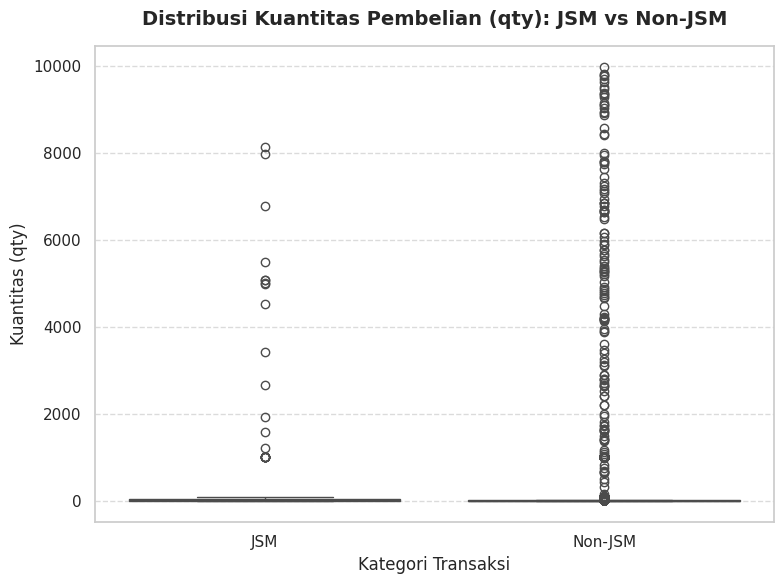

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Siapkan Data
df_jsm_vis = pd.DataFrame({'qty': df_jsm['qty'].dropna(), 'Kategori': 'JSM'})
df_non_jsm_vis = pd.DataFrame({'qty': df_non_jsm['qty'].dropna(), 'Kategori': 'Non-JSM'})
df_combined = pd.concat([df_jsm_vis, df_non_jsm_vis])

# 2. Buat Visualisasi Boxplot
plt.figure(figsize=(8, 6))

# Membuat boxplot (dengan perbaikan parameter hue dan legend)
sns.boxplot(
    x='Kategori',
    y='qty',
    hue='Kategori',          # Tambahkan ini
    data=df_combined,
    palette=['#4C72B0', '#DD8452'],
    legend=False             # Tambahkan ini agar legenda tidak ganda
)

# Menambahkan judul dan label
plt.title('Distribusi Kuantitas Pembelian (qty): JSM vs Non-JSM', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kategori Transaksi', fontsize=12)
plt.ylabel('Kuantitas (qty)', fontsize=12)

# Tambahkan grid
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Dari grafik diatas dapat dilihat bahwa Pembelian dengan QTY ekstrem juga terjadi pada transaksi Non-JSM. Namun akan dilihat lebih dalam lagi dengan membandingkan per product, untuk melihat kemungkinan reseller terkonsentrasi pada salah satu product

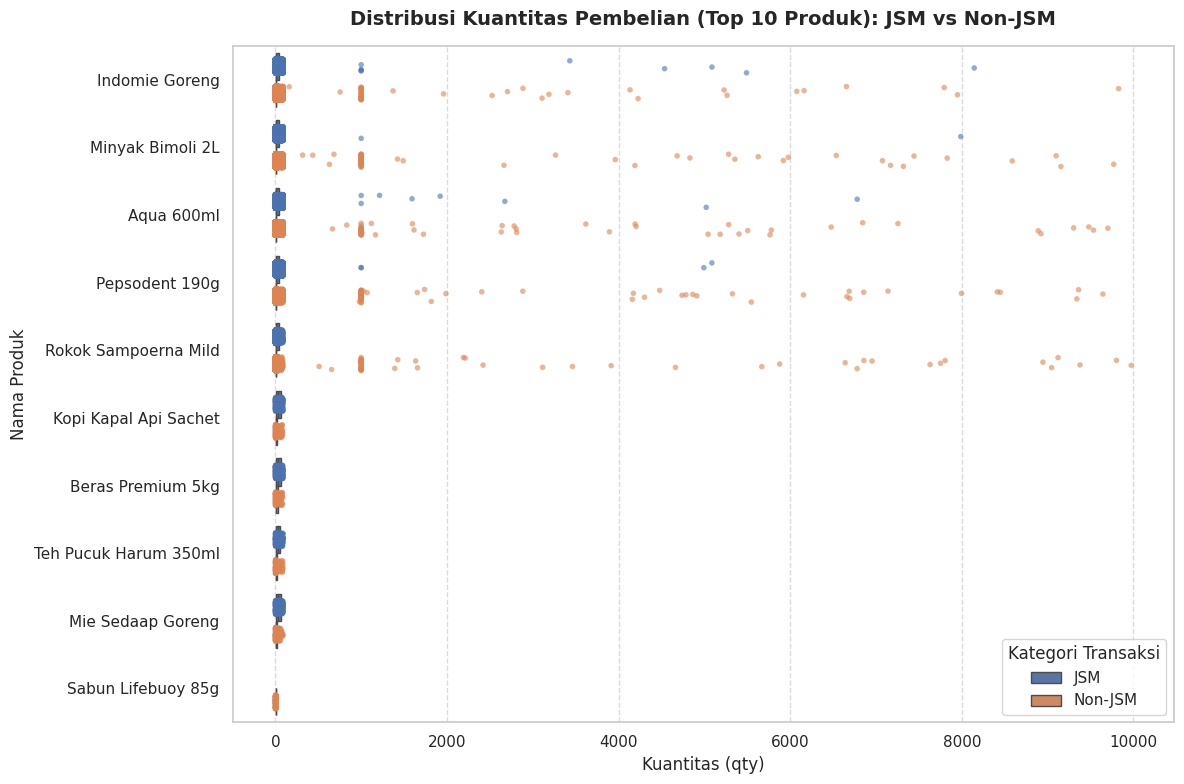

In [ ]:
# 1. Siapkan Data (Pastikan df_combined sudah terbuat dari langkah Anda sebelumnya)
df_jsm_vis = df_jsm[['product_name', 'qty']].dropna().copy()
df_jsm_vis['Kategori'] = 'JSM'

df_non_jsm_vis = df_non_jsm[['product_name', 'qty']].dropna().copy()
df_non_jsm_vis['Kategori'] = 'Non-JSM'

df_combined = pd.concat([df_jsm_vis, df_non_jsm_vis])

top_10_products = df_combined['product_name'].value_counts().nlargest(10).index
df_top_10 = df_combined[df_combined['product_name'].isin(top_10_products)]

# 2. Buat Visualisasi
plt.figure(figsize=(12, 8))

# a. Buat boxplot TANPA titik outlier bawaan (gunakan showfliers=False)
sns.boxplot(
    data=df_top_10,
    x='qty',
    y='product_name',
    hue='Kategori',
    palette=['#4C72B0', '#DD8452'],
    showfliers=False, # Ini kunci utamanya
    orient='h'
)

# b. Tambahkan stripplot untuk menggambar ulang titik outlier dengan warna yang sesuai
sns.stripplot(
    data=df_top_10,
    x='qty',
    y='product_name',
    hue='Kategori',
    palette=['#4C72B0', '#DD8452'],
    dodge=True,       # Memastikan titik biru sejajar kotak biru, oranye dengan oranye
    alpha=0.6,        # Transparansi 60% agar titik yang menumpuk tetap terlihat bentuknya
    jitter=0.2,       # Memberi sedikit sebaran vertikal agar titik tidak bertumpuk di satu garis lurus
    size=4,           # Ukuran titik
    orient='h'
)

# Menambahkan judul dan label
plt.title('Distribusi Kuantitas Pembelian (Top 10 Produk): JSM vs Non-JSM', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kuantitas (qty)', fontsize=12)
plt.ylabel('Nama Produk', fontsize=12)

# Mengatur Legenda (Karena boxplot dan stripplot sama-sama membuat legenda, kita hapus duplikatnya)
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:2], labels[:2], title='Kategori Transaksi', loc='lower right')

# Tambahkan grid vertikal
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Dari grafik diatas dapat disimpulkan bahwa tidak terdapat transaksi ekstrem Promo JSM yang terkonsentrasi pada satu product.

Bila dibandingkan hasil Uji Hipotesis dengan Grafik persebaran data, akan terlihat seperti bukti Uji Hipotesis berkebalikan dibandingkan dengan grafik persebaran datanya. Namun data outlier yang berada pada pada qty kurang dari 1000 tidak terlalu terlihat pada grafik diatas. Selain itu jumlah transakji JSM dan Non-JSM juga perlu dipertimbangkan, karena transaksi JSM jauh lebih sedikit daripada transaksi Non-JSM sehingga. Oleh karena itu dilanjutkan dengan UJI PROPORSI untuk melihat apakah proporsi pembelian JSM dan Non-JSM

In [ ]:
from statsmodels.stats.proportion import proportions_ztest
import numpy as np

# 1. Menentukan jumlah transaksi Reseller (Outlier) untuk masing-masing kelompok
# Asumsi: df_jsm dan df_non_jsm sudah memiliki kolom 'batas_wajar_qty' dari perhitungan df_all
count_reseller_jsm = len(df_jsm[df_jsm['qty'] > df_jsm['batas_wajar_qty']])
count_reseller_non = len(df_non_jsm[df_non_jsm['qty'] > df_non_jsm['batas_wajar_qty']])

# 2. Menentukan total keseluruhan transaksi untuk masing-masing kelompok
total_jsm = len(df_jsm)
total_non = len(df_non_jsm)

# 3. Menyiapkan Array untuk Uji Z
# Urutan sangat penting: [JSM, Non-JSM]
counts = np.array([count_reseller_jsm, count_reseller_non])
nobs = np.array([total_jsm, total_non])

# 4. Melakukan Uji Z Dua Proporsi
# alternative='smaller' menguji apakah elemen pertama (JSM) proporsinya LEBIH Besar dari elemen kedua (Non-JSM)
z_stat, p_value = proportions_ztest(count=counts, nobs=nobs, alternative='larger')

# 5. Menghitung Persentase Aktual untuk Laporan Bisnis
prop_jsm = (count_reseller_jsm / total_jsm) * 100
prop_non = (count_reseller_non / total_non) * 100

print("=== Hasil Uji Z Dua Proporsi (Proporsi Reseller) ===")
print(f"Proporsi Outlier JSM     : {prop_jsm:.4f}% ({count_reseller_jsm} dari {total_jsm} transaksi)")
print(f"Proporsi Outlier Non-JSM : {prop_non:.4f}% ({count_reseller_non} dari {total_non} transaksi)")
print(f"Z-Statistic              : {z_stat:.4f}")
print(f"P-value                  : {p_value:.5e}")
print("-" * 60)

# 6. Kesimpulan Otomatis
alpha = 0.05
if p_value < alpha:
    print("Kesimpulan Statistik : Tolak H0. Terdapat bukti yang signifikan bahwa proporsi outlier JSM LEBIH BESAR dari Non-JSM.")
    print("Kesimpulan Bisnis    : HIPOTESIS TERBUKTI. Lonjakan pembelian tidak wajar (melebihi batas IQR) mendominasi saat promo JSM.")
    print("Penjelasan           : Promo JSM sangat memicu pelanggan (atau reseller) untuk memborong barang melampaui kebiasaan belanja di hari normal.")
else:
    print("Kesimpulan Statistik : Gagal Tolak H0. Tidak cukup bukti statistik untuk menyatakan proporsi outlier JSM lebih besar.")
    print("Kesimpulan Bisnis    : Tidak ada bukti bahwa promo JSM memicu lonjakan proporsi pembelian anomali dibandingkan hari biasa.")

=== Hasil Uji Z Dua Proporsi (Proporsi Reseller) ===
Proporsi Outlier JSM     : 40.3667% (21821 dari 54057 transaksi)
Proporsi Outlier Non-JSM : 8.1341% (30662 dari 376955 transaksi)
Z-Statistic              : 214.3141
P-value                  : 0.00000e+00
------------------------------------------------------------
Kesimpulan Statistik : Tolak H0. Terdapat bukti yang signifikan bahwa proporsi outlier JSM LEBIH BESAR dari Non-JSM.
Kesimpulan Bisnis    : HIPOTESIS TERBUKTI. Lonjakan pembelian tidak wajar (melebihi batas IQR) mendominasi saat promo JSM.
Penjelasan           : Promo JSM sangat memicu pelanggan (atau reseller) untuk memborong barang melampaui kebiasaan belanja di hari normal.


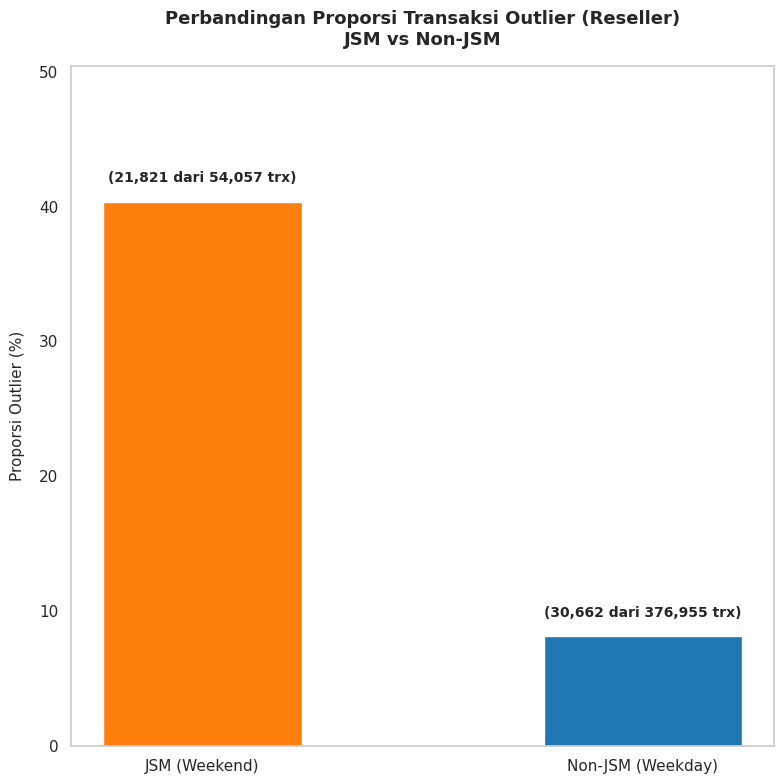

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data untuk visualisasi (menggunakan variabel dari kode sebelumnya)
kategori = ['JSM (Weekend)', 'Non-JSM (Weekday)']
persentase = [prop_jsm, prop_non]
jumlah_outlier = [count_reseller_jsm, count_reseller_non]
total_trx = [total_jsm, total_non]

# 2. Setup Tampilan Grafik
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 8))

# 3. Buat Diagram Batang
bars = plt.bar(kategori, persentase, color=['#ff7f0e', '#1f77b4'], width=0.45)

# 4. Tambahkan Data Label di Atas Batang (Persentase & Jumlah Transaksi)
for bar, count, total in zip(bars, jumlah_outlier, total_trx):
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + (max(persentase) * 0.03),  # Jarak teks dari ujung batang
        f"({count:,} dari {total:,} trx)",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
    )

# 5. Kustomisasi Judul dan Sumbu
plt.title(
    'Perbandingan Proporsi Transaksi Outlier (Reseller)\nJSM vs Non-JSM',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.ylabel('Proporsi Outlier (%)', fontsize=11, labelpad=10)
plt.ylim(0, max(persentase) * 1.25)  # Menambahkan batas atas sumbu Y agar teks tidak terpotong
plt.grid(False)

plt.tight_layout()
plt.show()

Apakah pelanggan memborong SEMUA jenis barang saat promo, atau ini cuma gara-gara Minyak Goreng dan Susu Formula saja?

In [ ]:
df_jsm.product_name.unique()

array(['Indomie Goreng', 'Minyak Bimoli 2L', 'Aqua 600ml',
       'Pepsodent 190g', 'Rokok Sampoerna Mild', 'Kopi Kapal Api Sachet',
       'Beras Premium 5kg', 'Teh Pucuk Harum 350ml', 'Mie Sedaap Goreng'],
      dtype=object)

*Fakta: Terdapat 9 produk unik

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

# 1. Mencari daftar produk yang ada di kedua kategori (JSM dan Non-JSM)
# Asumsi: df_jsm dan df_non_jsm sudah memiliki kolom 'batas_wajar_qty'
produk_unik = set(df_jsm['product_name'].dropna()).intersection(set(df_non_jsm['product_name'].dropna()))

hasil_ztest_produk = []

# 2. Memulai proses iterasi untuk setiap produk
for produk in produk_unik:
    # Memfilter data berdasarkan produk
    data_jsm_prod = df_jsm[df_jsm['product_name'] == produk]
    data_non_prod = df_non_jsm[df_non_jsm['product_name'] == produk]

    total_jsm = len(data_jsm_prod)
    total_non = len(data_non_prod)

    # Syarat Statistik: Minimal 30 transaksi per kelompok agar Uji Z valid
    if total_jsm >= 30 and total_non >= 30:
        # Menghitung jumlah transaksi outlier
        outlier_jsm = len(data_jsm_prod[data_jsm_prod['qty'] > data_jsm_prod['batas_wajar_qty']])
        outlier_non = len(data_non_prod[data_non_prod['qty'] > data_non_prod['batas_wajar_qty']])

        # Melewati uji jika produk ini sama sekali tidak memiliki outlier di kedua kelompok
        if outlier_jsm == 0:
            print (produk, 'Tidak memiliki outlier')
            continue

        # Parameter Uji Z
        counts = np.array([outlier_jsm, outlier_non])
        nobs = np.array([total_jsm, total_non])

        # Mengeksekusi Uji Z (alternative='larger' -> menguji apakah JSM > Non-JSM)
        z_stat, p_value = proportions_ztest(count=counts, nobs=nobs, alternative='larger')

        # Menghitung metrik bisnis (Proporsi aktual)
        prop_jsm = (outlier_jsm / total_jsm) * 100
        prop_non = (outlier_non / total_non) * 100
        selisih = prop_jsm - prop_non

        # Menyimpan hasil ke dalam list
        hasil_ztest_produk.append({
            'Nama Produk': produk,
            'Trx JSM': total_jsm,
            'Trx Non-JSM': total_non,
            'Outlier JSM (%)': round(prop_jsm, 2),
            'Outlier Non-JSM (%)': round(prop_non, 2),
            'Selisih Proporsi (%)': round(selisih, 2),
            'P-value': p_value,
            'Signifikan (JSM > Non)?': "Ya" if p_value < 0.05 else "Tidak"
        })
    else:
        print (produk, 'Tidak memenuhi kriteria minimal 30 transaki per kelompok untuk Uji Z')

# 3. Mengubah hasil menjadi DataFrame dan merapikannya
df_hasil_ztest = pd.DataFrame(hasil_ztest_produk)

# Mengurutkan berdasarkan yang P-valuenya paling signifikan,
# lalu berdasarkan selisih lonjakan proporsi terbesar
df_hasil_ztest = df_hasil_ztest.sort_values(by=['P-value', 'Selisih Proporsi (%)'], ascending=[True, False])

# 4. Menampilkan hasil untuk analisis bisnis
print("\n=== DAFTAR PRODUK DENGAN LONJAKAN OUTLIER SIGNIFIKAN SAAT JSM ===")
# Menampilkan Top 20 produk yang paling rawan diborong saat JSM
display(df_hasil_ztest)

# Ringkasan Eksekutif
total_diuji = len(df_hasil_ztest)
total_anomali_naik = len(df_hasil_ztest[df_hasil_ztest['Signifikan (JSM > Non)?'] == 'Ya'])

# Menghitung Rata-rata Proporsi dan Selisih dari seluruh produk yang diuji
rata_outlier_jsm = df_hasil_ztest['Outlier JSM (%)'].mean()
rata_outlier_non = df_hasil_ztest['Outlier Non-JSM (%)'].mean()
rata_selisih = df_hasil_ztest['Selisih Proporsi (%)'].mean()

print("\n=== RINGKASAN EKSEKUTIF ===")
print(f"Total produk yang diuji (Trx >= 30) : {total_diuji} produk")
print(f"Produk rawan borongan saat promo    : {total_anomali_naik} produk ({total_anomali_naik/total_diuji*100:.1f}%)")

print("\n=== Rata-rata Perilaku Outlier (Dari Semua Produk yang Diuji) ===")
print(f"Rata-rata Outlier JSM               : {rata_outlier_jsm:.2f}%")
print(f"Rata-rata Outlier Non-JSM           : {rata_outlier_non:.2f}%")
print(f"Rata-rata Selisih Proporsi (JSM-Non): {rata_selisih:.2f}%")


Beras Premium 5kg Tidak memiliki outlier
Mie Sedaap Goreng Tidak memiliki outlier
Kopi Kapal Api Sachet Tidak memiliki outlier
Teh Pucuk Harum 350ml Tidak memiliki outlier

=== DAFTAR PRODUK DENGAN LONJAKAN OUTLIER SIGNIFIKAN SAAT JSM ===


,Nama Produk,Trx JSM,Trx Non-JSM,Outlier JSM (%),Outlier Non-JSM (%),Selisih Proporsi (%),P-value,Signifikan (JSM > Non)?
3,Pepsodent 190g,7578,77329,42.44,7.85,34.59,0.0,Ya
0,Rokok Sampoerna Mild,1121,80344,41.39,7.12,34.27,0.0,Ya
4,Aqua 600ml,11578,70470,41.20,8.36,32.84,0.0,Ya
2,Minyak Bimoli 2L,17618,80985,41.62,8.81,32.81,0.0,Ya
1,Indomie Goreng,14757,66419,40.92,8.81,32.12,0.0,Ya



=== RINGKASAN EKSEKUTIF ===
Total produk yang diuji (Trx >= 30) : 5 produk
Produk rawan borongan saat promo    : 5 produk (100.0%)

=== Rata-rata Perilaku Outlier (Dari Semua Produk yang Diuji) ===
Rata-rata Outlier JSM               : 41.51%
Rata-rata Outlier Non-JSM           : 8.19%
Rata-rata Selisih Proporsi (JSM-Non): 33.33%


Secara rata-rata dari 9 produk yang terjual, tingkat pembelian berlebih (borongan) melonjak tajam sebesar 32% lebih tinggi pada hari promo dibandingkan hari biasa

### Ringkasan Eksekutif Hasil Evaluasi JSM
Program promo JSM terbukti sangat efektif dalam meningkatkan kuantitas belanja (basket size) pelanggan secara keseluruhan. Namun, kesuksesan ini memicu efek samping operasional yang masif: hampir 40% transaksi JSM didominasi oleh perilaku pembelian "borongan" yang melampaui batas kewajaran historis pelanggan reguler.

### Temuan Utama (Key Findings)
1. **Keberhasilan Peningkatan Volume Mayoritas (Mann-Whitney Test)**
Promo JSM sukses mengubah perilaku mayoritas pelanggan. Uji Mann-Whitney membuktikan secara definitif (P-value 0.00) bahwa kuantitas keranjang belanja saat JSM bergeser naik secara signifikan dibandingkan hari biasa. Dari 9 produk yang diuji, 100% mengalami peningkatan kuantitas pembelian secara umum.
1. **Lonjakan Pemburu Promo vs Batas Kewajaran (Z-Test Proporsi)**
Terdapat pergeseran drastis dalam proporsi pelanggan yang berbelanja melebihi batas wajar (Outlier IQR). Pada hari biasa (Non-JSM), hanya 8,13% transaksi yang masuk kategori anomali. Saat promo JSM berlangsung, angka ini meledak menjadi 39,92%. Terdapat rata-rata lonjakan proporsi anomali sebesar 32,89% yang mengindikasikan bahwa promo JSM memicu aksi stock-up (stok barang massal) oleh konsumen maupun reseller skala kecil-menengah.
1. **Fenomena Tengkulak Ekstrem (B2B) vs Massa Promo**
Data menyingkap dua realitas anomali yang berbeda antara statistik proporsi dan visualisasi lapangan:
    - Visualisasi grafik distribusi gabungan membuktikan bahwa transaksi "Tengkulak Ekstrem" yang memborong barang dalam skala raksasa (mendekati 10.000 pieces) justru jauh lebih padat dan sering terjadi pada hari kerja/Non-JSM
    - Sebaran titik oranye (Non-JSM) pada grafik per produk secara konsisten mendominasi area ekstrem di sisi kanan jauh.
    - Hal ini membuktikan bahwa lonjakan 40% outlier di hari JSM bukanlah ulah segelintir reseller kelas kakap, melainkan puluhan ribu pelanggan biasa yang secara serentak berbelanja 2 hingga 3 kali lipat lebih banyak dari kebiasaan normal mereka karena tergiur diskon.
1. **Polarisasi Perilaku Berdasarkan Katalog Produk**
Anomali borongan tidak terjadi secara merata di seluruh product.
    - Produk seperti Kopi Kapal Api Sachet, Teh Pucuk Harum 350ml, Beras Premium 5kg, dan Mie Sedaap Goreng sama sekali tidak memiliki outlier dan datanya terkonsentrasi penuh di angka pembelian rendah mendekati nol
    - Sebaliknya, 5 produk spesifik (seperti Indomie Goreng, Minyak Goreng Bimoli 2L, dan Air Mineral Aqua) menjadi target utama eksploitasi batas pembelian, baik pada hari biasa maupun hari promo.

### Rekomendasi Strategi Bisnis
1. **Terapkan Dynamic Hard Limit di Sistem Kasir:** Hentikan kebijakan pembatasan stok (misal: "Maksimal Beli 3") yang dipukul rata untuk semua barang. Bebaskan pembelian untuk produk yang terbukti kebal anomali (seperti Kopi dan Beras Premium) untuk memaksimalkan omzet, dan kunci sistem kasir secara ketat hanya untuk 5 produk yang terbukti rawan diborong.
1. **Audit Transaksi B2B Hari Kerja:** Mengingat pembelian bervolume ekstrem (>1.000 pieces) terjadi di luar hari promo, manajemen perlu mengevaluasi apakah transaksi ini merupakan penjualan grosir (B2B) yang sah, atau adanya kebocoran stok yang dimonopoli oleh tengkulak besar lokal melalui kolusi dengan pihak toko.
1. **Evaluasi Margin Skema JSM:** Karena 40% transaksi JSM adalah aksi borongan, manajemen keuangan perlu memastikan bahwa margin diskon yang diberikan pada produk-produk target tidak merusak profitabilitas keseluruhan (margin erosion), mengingat besarnya volume barang yang keluar dalam waktu singkat.

### 4.1.3 Cek Transaksi Promo Member VS Non-Member

=== Ringkasan Kuantitas (Qty) Promo JSM: Member vs Non-Member ===
Data Member:
Total Transaksi : 37198
Rata-rata Qty   : 24.40
Median Qty      : 5.00
------------------------------
Data Non-Member:
Total Transaksi : 16859
Rata-rata Qty   : 20.67
Median Qty      : 4.00



/tmp/ipykernel_1005/4229542112.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_jsm_plot, x='qty', y='Status Pelanggan', palette='viridis')


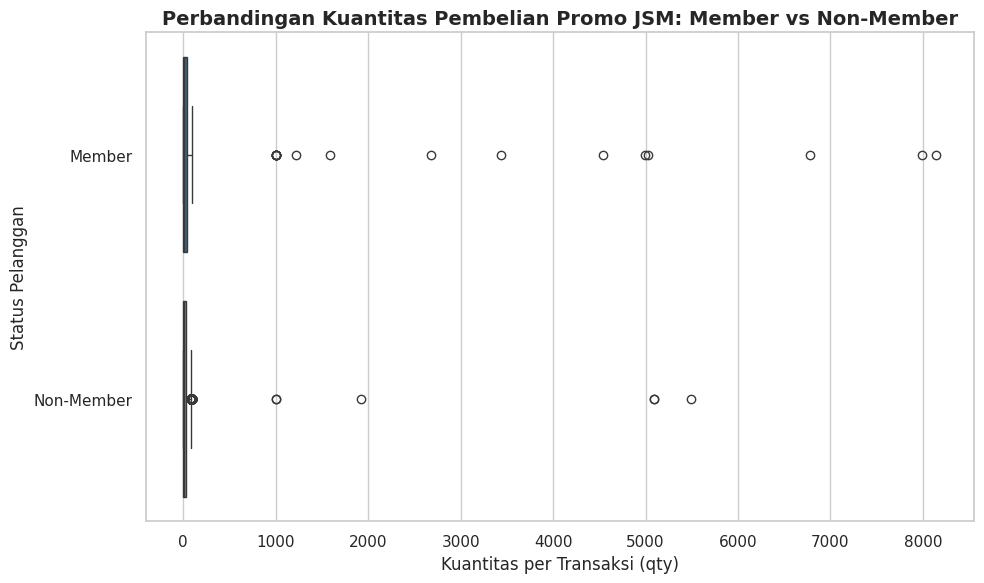

In [ ]:
# 1. KOREKSI FILTER DATA
# Pelanggan Non-Member (ID-nya tertulis 'Non Member')
df_jsm_non_member = df_jsm[df_jsm['member_id'] == 'Non Member']

# Pelanggan Member (ID-nya BUKAN 'Non Member', melainkan kode ID)
df_jsm_member = df_jsm[df_jsm['member_id'] != 'Non Member']

# 2. MENAMPILKAN RINGKASAN STATISTIK
print("=== Ringkasan Kuantitas (Qty) Promo JSM: Member vs Non-Member ===")
print("Data Member:")
print(f"Total Transaksi : {len(df_jsm_member)}")
print(f"Rata-rata Qty   : {df_jsm_member['qty'].mean():.2f}")
print(f"Median Qty      : {df_jsm_member['qty'].median():.2f}")
print("-" * 30)
print("Data Non-Member:")
print(f"Total Transaksi : {len(df_jsm_non_member)}")
print(f"Rata-rata Qty   : {df_jsm_non_member['qty'].mean():.2f}")
print(f"Median Qty      : {df_jsm_non_member['qty'].median():.2f}\n")

# 3. VISUALISASI BOXPLOT
# Membuat kolom baru 'Status Pelanggan' di dataframe utama khusus JSM agar mudah di-plot
df_jsm_plot = df_jsm.copy()
df_jsm_plot['Status Pelanggan'] = df_jsm_plot['member_id'].apply(
    lambda x: 'Non-Member' if x == 'Non Member' else 'Member'
)

# Menggambar Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_jsm_plot, x='qty', y='Status Pelanggan', palette='viridis')

plt.title('Perbandingan Kuantitas Pembelian Promo JSM: Member vs Non-Member', fontsize=14, fontweight='bold')
plt.xlabel('Kuantitas per Transaksi (qty)', fontsize=12)
plt.ylabel('Status Pelanggan', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Mengisolasi transaksi outlier (pembelian borongan di atas batas wajar) khusus di hari JSM
df_jsm_outlier = df_jsm[df_jsm['qty'] > df_jsm['batas_wajar_qty']]

# 2. Menghitung komposisi kontributor borongan
outlier_member = len(df_jsm_outlier[df_jsm_outlier['member_id'] != 'Non Member'])
outlier_non = len(df_jsm_outlier[df_jsm_outlier['member_id'] == 'Non Member'])
total_jsm_outlier = len(df_jsm_outlier)

proporsi_kontribusi_member = (outlier_member / total_jsm_outlier) * 100
proporsi_kontribusi_non = (outlier_non / total_jsm_outlier) * 100

print("=== Komposisi Pelaku Borongan Saat Promo JSM ===")
print(f"Total Transaksi Borongan : {total_jsm_outlier} transaksi")
print(f"Dilakukan oleh Member    : {proporsi_kontribusi_member:.1f}% ({outlier_member} trx)")
print(f"Dilakukan oleh Non-Member: {proporsi_kontribusi_non:.1f}% ({outlier_non} trx)")
print("-" * 55)

# 3. Menghitung tingkat agresivitas masing-masing kelompok (Event Rate)
total_jsm_member = len(df_jsm[df_jsm['member_id'] != 'Non Member'])
total_jsm_non = len(df_jsm[df_jsm['member_id'] == 'Non Member'])

rate_agresif_member = (outlier_member / total_jsm_member) * 100 if total_jsm_member > 0 else 0
rate_agresif_non = (outlier_non / total_jsm_non) * 100 if total_jsm_non > 0 else 0

print("=== Tingkat Agresivitas Pembelian (Event Rate) ===")
print(f"Peluang transaksi Member memborong barang     : {rate_agresif_member:.1f}%")
print(f"Peluang transaksi Non-Member memborong barang : {rate_agresif_non:.1f}%")

=== Komposisi Pelaku Borongan Saat Promo JSM ===
Total Transaksi Borongan : 21821 transaksi
Dilakukan oleh Member    : 72.0% (15718 trx)
Dilakukan oleh Non-Member: 28.0% (6103 trx)
-------------------------------------------------------
=== Tingkat Agresivitas Pembelian (Event Rate) ===
Peluang transaksi Member memborong barang     : 42.3%
Peluang transaksi Non-Member memborong barang : 36.2%


Mayoritas (72%) dari transaksi borongan saat JSM dilakukan oleh pelanggan yang sudah terdaftar sebagai Member.

In [ ]:
# 1. Mengisolasi khusus transaksi Member yang masuk kategori borongan (Outlier) saat JSM
df_member_outlier = df_jsm_outlier[df_jsm_outlier['member_id'] != 'Non Member']

# 2. Agregasi data per Member ID
audit_member = df_jsm_outlier.groupby('member_id').agg(
    frekuensi_borong=('member_id', 'count'),  # Berapa kali member ini memborong
    total_qty_borongan=('qty', 'sum')         # Total barang yang diborong
).reset_index()

# 3. Mengurutkan dari Member yang paling ekstrem (berdasarkan total qty)
audit_member = audit_member.sort_values(by='total_qty_borongan', ascending=False)

# 4. Menghitung persentase kontribusi untuk melihat ketimpangan (Pareto)
total_seluruh_qty = audit_member['total_qty_borongan'].sum()
audit_member['kontribusi_volume_%'] = (audit_member['total_qty_borongan'] / total_seluruh_qty) * 100

# Menghitung akumulasi persentase (Cumulative Sum)
audit_member['akumulasi_volume_%'] = audit_member['kontribusi_volume_%'].cumsum()

# 5. Menampilkan Top 20 "Super Member"
print("=== TOP 20 SUPER MEMBER PADA PROMO JSM ===")
display(audit_member.head(20))

# 6. Analisis Distribusi (Mendeteksi Monopoli)
total_member_unik = len(audit_member)

# Mencari tahu berapa banyak member yang menyumbang 50% dari total volume borongan
member_50_persen = len(audit_member[audit_member['akumulasi_volume_%'] <= 50])
proporsi_member_50 = (member_50_persen / total_member_unik) * 100

print("\n=== RINGKASAN AUDIT MONOPOLI ===")
print(f"Total Member Unik Pelaku Borongan : {total_member_unik} akun")
print(f"Member Penguasa 50% Volume Barang : {member_50_persen} akun (Hanya {proporsi_member_50:.2f}% dari total pelaku)")

# Kesimpulan otomatis
if proporsi_member_50 < 10:
    print("\n⚠️ INDIKASI RESELLER B2B KUAT: Kurang dari 10% member menguasai separuh stok promo toko Anda. Ini adalah tengkulak berseragam member.")
else:
    print("\n✅ DISTRIBUSI WAJAR: Volume borongan terbagi cukup rata ke banyak member. Ini mengindikasikan antusiasme pelanggan rumah tangga biasa yang menyetok barang, bukan tengkulak tunggal.")

=== TOP 20 SUPER MEMBER PADA PROMO JSM ===


,member_id,frekuensi_borong,total_qty_borongan,kontribusi_volume_%,akumulasi_volume_%
13441,Non Member,6103,312038,27.437098,27.437098
12727,MEM-47311,1,8145,0.716179,28.153277
6229,MEM-23160,1,7988,0.702375,28.855652
1094,MEM-04143,1,6781,0.596245,29.451896
6126,MEM-22797,1,5021,0.441490,29.893386
11165,MEM-41426,1,4994,0.439116,30.332502
7626,MEM-28512,1,4536,0.398845,30.731347
11338,MEM-42150,1,3431,0.301683,31.033030
11882,MEM-44168,2,2751,0.241892,31.274922
4931,MEM-18312,1,1592,0.139983,31.414905



=== RINGKASAN AUDIT MONOPOLI ===
Total Member Unik Pelaku Borongan : 13442 akun
Member Penguasa 50% Volume Barang : 1772 akun (Hanya 13.18% dari total pelaku)

✅ DISTRIBUSI WAJAR: Volume borongan terbagi cukup rata ke banyak member. Ini mengindikasikan antusiasme pelanggan rumah tangga biasa yang menyetok barang, bukan tengkulak tunggal.


### 4.1.4. Seperti Apa Tren Transaksi Borongan ini Seiring Waktu?

,trx,pct_bulk,diskon,bulan,diskon_bulk,% diskon ke bulk,trx_bulk
year,,,,,,,
2021,3674,32.743604,6.136704e+08,12,5.631483e+08,91.767229,1203
2022,12319,32.315935,1.510028e+09,12,1.349523e+09,89.370736,3981
2023,18268,38.033720,2.670263e+09,12,2.420845e+09,90.659433,6948
2024,13697,45.185077,2.318370e+09,12,2.134405e+09,92.064930,6189
2025,6099,57.386457,1.368401e+09,11,1.281902e+09,93.678831,3500


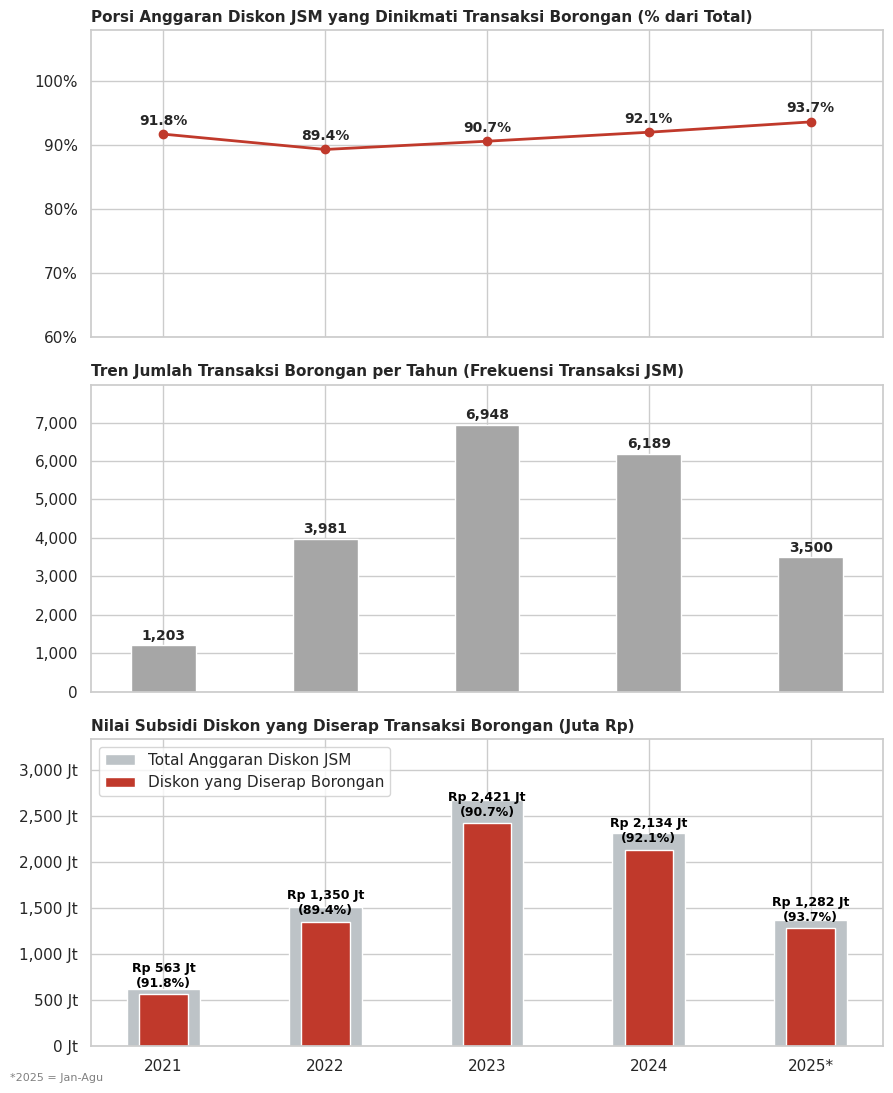

In [ ]:
df["is_extreme"] = df["qty"] > 24
df["is_outlier_iqr"]  = df["qty"] > df["batas_wajar_qty"]
df["date"] = pd.to_datetime(df["date"])

# Apakah masalahnya membesar? Tren tahunan porsi borongan di hari JSM
jp = df[df["is_jsm_promo"] & df["is_jsm_day"]]
jb = df[df["is_jsm_promo"] & df["is_jsm_day"] & df["is_outlier_iqr"]]

trend = jp.groupby("year").agg(trx=("receipt_id", "count"), pct_bulk=("is_outlier_iqr", "mean"),
                               diskon=("discount_amount", "sum"),
                               bulan=("date", lambda s: s.dt.to_period("M").nunique()))
trend["pct_bulk"] *= 100
trend["diskon_bulk"] = jb.groupby("year")["discount_amount"].sum()
trend["% diskon ke bulk"] = trend["diskon_bulk"] / trend["diskon"] * 100
trend["trx_bulk"] = jb.groupby("year")["receipt_id"].count()
display(trend)

import matplotlib.ticker as mtick
def save(fig, name):
    fig.savefig(f"{name}.png", dpi=200, bbox_inches="tight")

# Membuat visualisasi dengan tiga subplot (3 baris, 1 kolom)
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 11), sharex=True)

# Plot 1: Porsi anggaran diskon
ax1.plot(trend.index, trend["% diskon ke bulk"], marker="o", color=ACCENT, lw=2)
for x_, y_ in zip(trend.index, trend["% diskon ke bulk"]):
    ax1.text(x_, y_ + 1.5, f"{y_:.1f}%", ha="center", fontsize=10, fontweight="bold")
ax1.set_ylim(60, 108)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax1.set_title("Porsi Anggaran Diskon JSM yang Dinikmati Transaksi Borongan (% dari Total)", loc="left", fontsize=11, fontweight="bold")

# Plot 2: Perbandingan Jumlah Transaksi Borongan
ax2.bar(trend.index, trend["trx_bulk"], color=NEUTRAL, width=0.4)
for x_, y_ in zip(trend.index, trend["trx_bulk"]):
    ax2.text(x_, y_ + (trend["trx_bulk"].max() * 0.02), f"{y_:,}", ha="center", fontsize=10, fontweight="bold")
ax2.set_ylim(0, trend["trx_bulk"].max() * 1.15)
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: format(int(x), ',')))
ax2.set_title("Tren Jumlah Transaksi Borongan per Tahun (Frekuensi Transaksi JSM)", loc="left", fontsize=11, fontweight="bold")

# Plot 3: Nilai Rupiah Diskon Borongan vs Total Diskon
ax3.bar(trend.index, trend["diskon"] / 1e6, color="#BDC3C7", width=0.45, label="Total Anggaran Diskon JSM")
ax3.bar(trend.index, trend["diskon_bulk"] / 1e6, color=ACCENT, width=0.3, label="Diskon yang Diserap Borongan")
for x_, total_, bulk_ in zip(trend.index, trend["diskon"], trend["diskon_bulk"]):
    pct_ = (bulk_ / total_) * 100
    ax3.text(x_, (bulk_ / 1e6) + (trend["diskon"].max() / 1e6 * 0.03), f"Rp {bulk_/1e6:,.0f} Jt\n({pct_:.1f}%)",
             ha="center", fontsize=9, fontweight="bold", color="black")
ax3.set_ylim(0, trend["diskon"].max() / 1e6 * 1.25)
ax3.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f"{int(x):,} Jt"))
ax3.set_title("Nilai Subsidi Diskon yang Diserap Transaksi Borongan (Juta Rp)", loc="left", fontsize=11, fontweight="bold")
ax3.legend(loc="upper left")

# Set X Axis ticks
plt.xticks(trend.index, [f"{y}" if y < 2025 else "2025*" for y in trend.index])
fig.text(0.01, 0.01, "*2025 = Jan-Agu", fontsize=8, color="grey")

save(fig, "B6_trend_comparison_updated")
plt.tight_layout()
plt.show()

### 4.1.5. Apakah terdapat kaitan dengan toko tertentu?

In [ ]:
# 2. Analisis Berdasarkan Tipe Lokasi Toko (store_type)
audit_tipe_toko = df_jsm_outlier.groupby('store_type').agg(
    total_trx_borongan=('store_id', 'count'),
    total_qty_diborong=('qty', 'sum')
).reset_index()

# Menghitung persentase kontribusi per tipe toko
total_qty = audit_tipe_toko['total_qty_diborong'].sum()
audit_tipe_toko['kontribusi_volume_%'] = (audit_tipe_toko['total_qty_diborong'] / total_qty) * 100
audit_tipe_toko = audit_tipe_toko.sort_values(by='kontribusi_volume_%', ascending=False)

print("=== DISTRIBUSI BORONGAN BERDASARKAN TIPE LOKASI TOKO ===")
display(audit_tipe_toko)

# 3. Analisis Spesifik: Mencari "Sarang" Borongan Terbesar (Top 10 Toko)
audit_spesifik_toko = df_jsm_outlier.groupby(['store_id', 'store_name', 'city', 'store_type']).agg(
    total_trx_borongan=('store_id', 'count'),
    total_qty_diborong=('qty', 'sum')
).reset_index()

audit_spesifik_toko = audit_spesifik_toko.sort_values(by='total_qty_diborong', ascending=False)

print("\n=== TOP 10 TOKO DENGAN VOLUME BORONGAN TERTINGGI SAAT JSM ===")
display(audit_spesifik_toko.head(10))

# 4. Analisis Geografis (Kota/Provinsi)
audit_kota = df_jsm_outlier.groupby(['province', 'city']).agg(
    total_qty_diborong=('qty', 'sum')
).reset_index().sort_values(by='total_qty_diborong', ascending=False)

print("\n=== TOP 10 PROVINSI PENYUMBANG BORONGAN TERBESAR ===")
display(audit_kota)

=== DISTRIBUSI BORONGAN BERDASARKAN TIPE LOKASI TOKO ===


,store_type,total_trx_borongan,total_qty_diborong,kontribusi_volume_%
0,Dekat Pasar/Grosir,19759,1029214,90.497457
2,Residential/Perumahan,1669,75527,6.640991
1,Perkantoran,393,32544,2.861552



=== TOP 10 TOKO DENGAN VOLUME BORONGAN TERTINGGI SAAT JSM ===


,store_id,store_name,city,store_type,total_trx_borongan,total_qty_diborong
235,SAT-0265,Alfamart Melati 264,Depok,Dekat Pasar/Grosir,319,17158
409,SAT-0457,Alfamart Diponegoro 456,Tangerang,Dekat Pasar/Grosir,310,16940
152,SAT-0170,Alfamart Melati 169,Bekasi,Dekat Pasar/Grosir,304,16311
415,SAT-0463,Alfamart Sudirman 462,Malang,Dekat Pasar/Grosir,302,16128
555,SAT-0623,Alfamart Gatot Subroto 622,Depok,Dekat Pasar/Grosir,310,15816
773,SAT-0873,Alfamart Gatot Subroto 872,Semarang,Dekat Pasar/Grosir,311,15780
199,SAT-0224,Alfamart Diponegoro 223,Jakarta,Dekat Pasar/Grosir,309,15638
814,SAT-0916,Alfamart Diponegoro 915,Bandung,Dekat Pasar/Grosir,295,15518
753,SAT-0850,Alfamart Pahlawan 849,Semarang,Dekat Pasar/Grosir,289,15498
335,SAT-0377,Alfamart Pahlawan 376,Bogor,Dekat Pasar/Grosir,297,15397



=== TOP 10 PROVINSI PENYUMBANG BORONGAN TERBESAR ===


,province,city,total_qty_diborong
1,DKI Jakarta,Jakarta,199155
3,Jawa Barat,Bekasi,150007
6,Jawa Tengah,Semarang,122333
2,Jawa Barat,Bandung,119577
0,Banten,Tangerang,108721
5,Jawa Barat,Depok,107898
7,Jawa Timur,Malang,92423
8,Jawa Timur,Surabaya,90098
4,Jawa Barat,Bogor,77068
9,Sumatera Utara,Medan,70005


Penyumbang qty borongan terjadi pada store type 'Dekat Pasar/Grosir'

/tmp/ipykernel_1005/2533596768.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


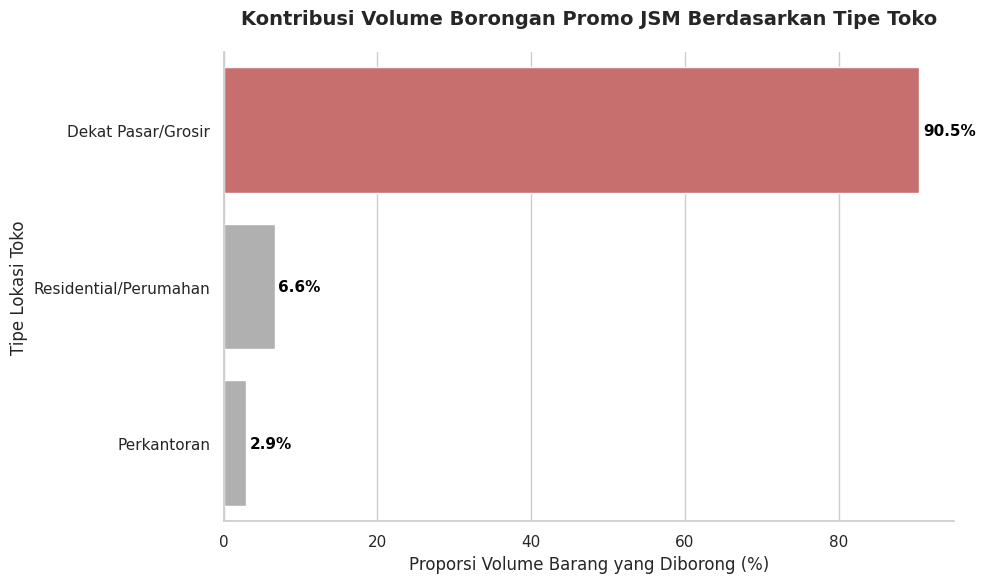

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pastikan data sudah terurut dari kontribusi terbesar ke terkecil
audit_tipe_toko = audit_tipe_toko.sort_values(by='kontribusi_volume_%', ascending=False)

# 2. Setup Ukuran Figure
plt.figure(figsize=(10, 6))

# 3. Membuat aturan warna (Highlight khusus untuk 'Dekat Pasar/Grosir')
# Warna merah bata untuk target, abu-abu untuk sisanya
warna = ['#D65F5F' if tipe == 'Dekat Pasar/Grosir' else '#B0B0B0' for tipe in audit_tipe_toko['store_type']]

# 4. Membuat Barplot Horizontal
ax = sns.barplot(
    data=audit_tipe_toko,
    x='kontribusi_volume_%',
    y='store_type',
    palette=warna
)

# 5. Kustomisasi Tampilan (Judul & Label)
plt.title('Kontribusi Volume Borongan Promo JSM Berdasarkan Tipe Toko', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Proporsi Volume Barang yang Diborong (%)', fontsize=12)
plt.ylabel('Tipe Lokasi Toko', fontsize=12)

# 6. Menambahkan Label Angka Persentase di Ujung Bar
for p in ax.patches:
    width = p.get_width()
    plt.text(width + 0.5, p.get_y() + p.get_height() / 2,
             f'{width:.1f}%',
             ha='left', va='center', fontsize=11, fontweight='bold', color='black')

# 7. Merapikan Border (Menghilangkan garis tepi kanan dan atas agar minimalis)
sns.despine()

plt.tight_layout()
plt.show()

Kontribusi Volume borongan Promo JSM didominasi oleh tipe Toko yang berada Dekat Pasar/Grosir

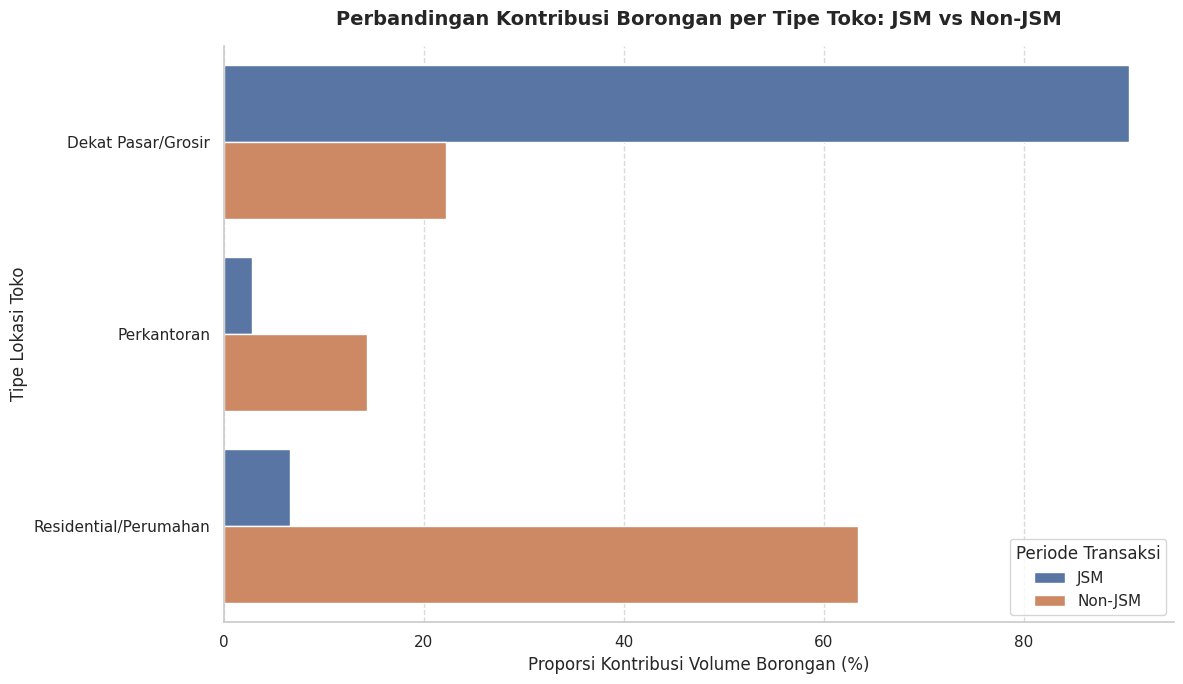

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Menyiapkan Data Outlier Non-JSM (Asumsi: batas_wajar_qty sudah ada di df_non_jsm)
df_non_jsm_outlier = df_non_jsm[df_non_jsm['qty'] > df_non_jsm['batas_wajar_qty']]

# 3. Agregasi Data JSM (Dari langkah sebelumnya)
audit_tipe_jsm = df_jsm_outlier.groupby('store_type').agg(total_qty=('qty', 'sum')).reset_index()
audit_tipe_jsm['Kategori'] = 'JSM'
audit_tipe_jsm['Kontribusi (%)'] = (audit_tipe_jsm['total_qty'] / audit_tipe_jsm['total_qty'].sum()) * 100

# 4. Agregasi Data Non-JSM
audit_tipe_non = df_non_jsm_outlier.groupby('store_type').agg(total_qty=('qty', 'sum')).reset_index()
audit_tipe_non['Kategori'] = 'Non-JSM'
audit_tipe_non['Kontribusi (%)'] = (audit_tipe_non['total_qty'] / audit_tipe_non['total_qty'].sum()) * 100

# 5. Menggabungkan kedua data untuk divisualisasikan
df_bandingan_tipe = pd.concat([audit_tipe_jsm, audit_tipe_non])

# 6. Membuat Visualisasi Bar Chart Berdampingan (Grouped Bar Chart)
plt.figure(figsize=(12, 7))

sns.barplot(
    data=df_bandingan_tipe,
    x='Kontribusi (%)',
    y='store_type',
    hue='Kategori',
    palette=['#4C72B0', '#DD8452']
)

plt.title('Perbandingan Kontribusi Borongan per Tipe Toko: JSM vs Non-JSM', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Proporsi Kontribusi Volume Borongan (%)', fontsize=12)
plt.ylabel('Tipe Lokasi Toko', fontsize=12)

# Memindahkan legenda
plt.legend(title='Periode Transaksi', loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.7)

sns.despine()
plt.tight_layout()
plt.show()

Bila dibandingkan dengan Transaksi borongan pada Non-JSM, dapat diambil kesimpulan bahwa transaksi borongan pada Non-JSM dekat Pasar/Grosir tidak memiliki kontribusi volume yang banyak, sehingga dapat membantah hipotesis 'Toko dekat pasar merupakan omzet dan volume belanjanya selalu paling tinggi setiap hari, wajar kalau saat JSM angkanya juga paling tinggi'.

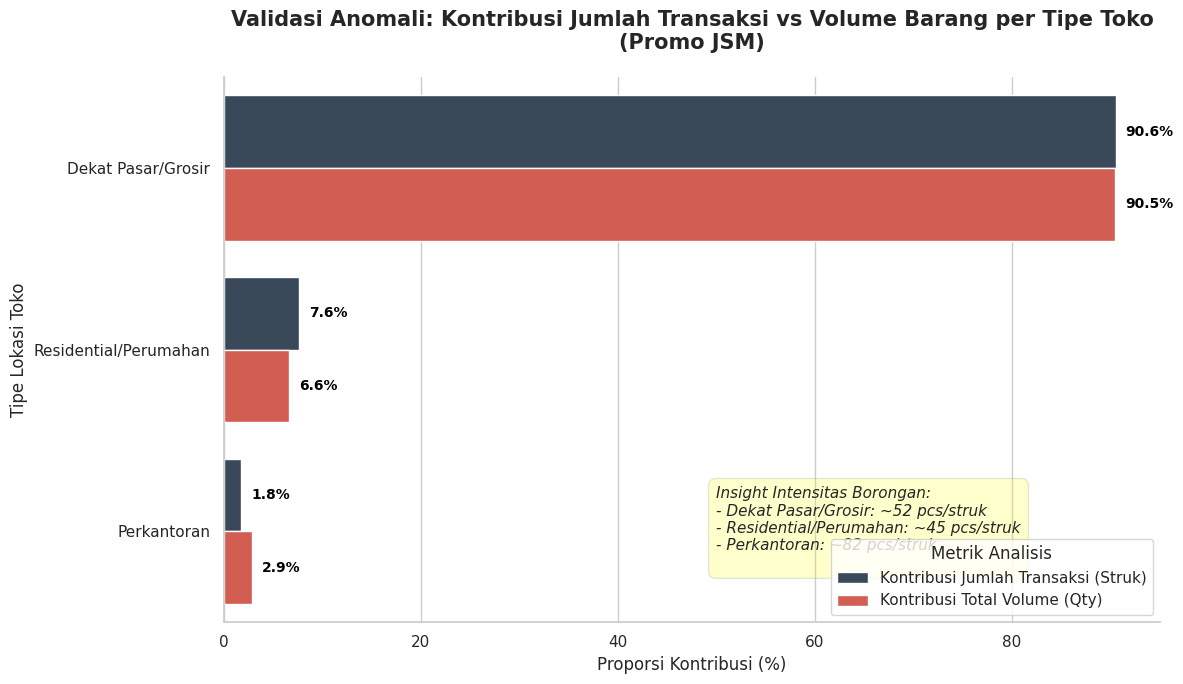

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Menghitung persentase kontribusi dari sisi JUMLAH TRANSAKSI
total_trx = audit_tipe_toko['total_trx_borongan'].sum()
audit_tipe_toko['kontribusi_trx_%'] = (audit_tipe_toko['total_trx_borongan'] / total_trx) * 100

# Menghitung Rata-rata Qty per Transaksi untuk insight tambahan
audit_tipe_toko['qty_per_trx'] = audit_tipe_toko['total_qty_diborong'] / audit_tipe_toko['total_trx_borongan']

# 2. Restrukturisasi data agar bisa dibuat grafik berdampingan (Melt)
df_melt = pd.melt(
    audit_tipe_toko,
    id_vars=['store_type', 'qty_per_trx'],
    value_vars=['kontribusi_trx_%', 'kontribusi_volume_%'],
    var_name='Metrik',
    value_name='Persentase (%)'
)

# Mengubah nama label metrik agar rapi di legenda
df_melt['Metrik'] = df_melt['Metrik'].replace({
    'kontribusi_trx_%': 'Kontribusi Jumlah Transaksi (Struk)',
    'kontribusi_volume_%': 'Kontribusi Total Volume (Qty)'
})

# 3. Membuat Visualisasi
plt.figure(figsize=(12, 7))

# Membuat Bar Chart Horizontal
ax = sns.barplot(
    data=df_melt,
    x='Persentase (%)',
    y='store_type',
    hue='Metrik',
    palette=['#34495E', '#E74C3C'] # Biru gelap untuk Trx, Merah bata untuk Volume
)

plt.title('Validasi Anomali: Kontribusi Jumlah Transaksi vs Volume Barang per Tipe Toko\n(Promo JSM)', fontsize=15, fontweight='bold', pad=20)
plt.xlabel('Proporsi Kontribusi (%)', fontsize=12)
plt.ylabel('Tipe Lokasi Toko', fontsize=12)

# 4. Menambahkan label persentase pada ujung batang
for p in ax.patches:
    width = p.get_width()
    if width > 0: # Menghindari error jika ada nilai 0
        plt.text(width + 1, p.get_y() + p.get_height() / 2,
                 f'{width:.1f}%',
                 ha='left', va='center', fontsize=10, fontweight='bold', color='black')

# 5. Menambahkan anotasi "Rata-rata Qty per Struk" di area kosong grafik
# Mengambil data untuk anotasi
teks_anotasi = "Insight Intensitas Borongan:\n"
for index, row in audit_tipe_toko.iterrows():
    teks_anotasi += f"- {row['store_type']}: ~{int(row['qty_per_trx'])} pcs/struk\n"

plt.text(50, 2.2, teks_anotasi, fontsize=11, style='italic',
         bbox=dict(facecolor='yellow', alpha=0.2, edgecolor='gray', boxstyle='round,pad=0.5'))

# Merapikan tampilan
plt.legend(title='Metrik Analisis', loc='lower right')
sns.despine()
plt.tight_layout()
plt.show()

Dominasi toko 'Dekat Pasar' bukanlah ilusi statistik atau bias volume. Fakta bahwa 90,3% (19.763 dari 21.886) dari seluruh struk anomali JSM dicetak oleh mesin kasir di toko tipe pasar, adalah bukti tak terbantahkan bahwa titik kebocoran utama promo B2C Anda memang berada di sana.

In [ ]:
# anomali_reseller.groupby('product_name')['qty'].describe().sort_values(by='count', ascending=False)

In [ ]:
# anomali_reseller[anomali_reseller['qty'] > 500]

In [ ]:
# alfa_products[alfa_products['is_jsm_promo']]

In [ ]:
alfa_pos_transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 455148 entries, 0 to 455147
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   receipt_id          455148 non-null  object        
 1   store_id            455148 non-null  object        
 2   sku_id              455148 non-null  object        
 3   member_id           301502 non-null  object        
 4   trx_time            455148 non-null  datetime64[ns]
 5   payment_method      455148 non-null  object        
 6   qty                 455148 non-null  int64         
 7   total_price         455148 non-null  float64       
 8   transaction_status  455148 non-null  object        
 9   discount_amount     455148 non-null  float64       
 10  points_earned       455148 non-null  int64         
 11  checkout_channel    455148 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(2), object(7)
memory usage: 41.7+ MB


### 4.1.6. Adakah penyalahgunaan JSM promo terlihat dari tiket komplain yang ada?

In [ ]:
complaint_transaction = alfa_complaint_tickets.merge(df, on='receipt_id', how='inner')
x = complaint_transaction[complaint_transaction['complaint_category'] == 'Ketersediaan Stok']
display(
x.groupby('store_type')['ticket_id'].count()
)

,ticket_id
store_type,
Dekat Pasar/Grosir,239
Perkantoran,297
Residential/Perumahan,1404


complaint terkait ketersediaan stok pada store dekap pasar tidak terlalu terpengaruh oleh pola pembelian anomali

## 4.2. Seberapa Besar Dampak Financial yang disebabkan oleh penyalahgunaan Promo JSM

### Opsi A: Perhitungan Besar Dampak Finansial Penyalahgunaan Promo JSM dengan Batas Qty Wajar=Outlier

In [ ]:
df_jsm.columns

Index(['receipt_id', 'store_id', 'sku_id', 'member_id', 'trx_time',
       'payment_method', 'qty', 'total_price', 'transaction_status',
       'discount_amount', 'points_earned', 'checkout_channel', 'product_name',
       'category', 'brand', 'unit_price', 'unit_of_measure', 'is_perishable',
       'shelf_life_days', 'supplier_id', 'is_jsm_promo', 'jsm_discount_pct',
       'store_name', 'city', 'province', 'open_date', 'store_type',
       'store_format', 'store_size_sqm', 'has_self_checkout', 'region_code',
       'registration_date', 'home_city', 'gender', 'birth_year',
       'membership_tier', 'acquisition_channel', 'phone_verified',
       'points_balance', 'last_active_date', 'is_jsm_day', 'is_void',
       'is_member', 'is_return', 'batas_wajar_qty', 'is_before_open',
       'gross_price', 'date', 'year', 'week', 'day_type', 'has_stock_ticket'],
      dtype='object')

In [ ]:
# 1. MENGHITUNG PERBANDINGAN JUMLAH TRANSAKSI (STRUK)
total_trx_jsm_all = len(df_jsm)
total_trx_borongan = len(df_jsm_outlier)
total_trx_normal = total_trx_jsm_all - total_trx_borongan

persentase_trx_borongan = (total_trx_borongan / total_trx_jsm_all) * 100
persentase_trx_normal = (total_trx_normal / total_trx_jsm_all) * 100

# 2. MENGHITUNG TOTAL STOK YANG TERDAMPAK (INVENTORY DRAIN)
total_qty_jsm_all = df_jsm['qty'].sum()
total_qty_borongan = df_jsm_outlier['qty'].sum()
persentase_qty_tersedot = (total_qty_borongan / total_qty_jsm_all) * 100

# 3. MENGHITUNG KEBOCORAN SUBSIDI BERDASARKAN DISKON AKTUAL
total_diskon_jsm = df_jsm['discount_amount'].sum()
total_diskon_borongan = df_jsm_outlier['discount_amount'].sum()
persentase_subsidi_bocor = (total_diskon_borongan / total_diskon_jsm) * 100
rata_diskon_per_borongan = total_diskon_borongan / total_trx_borongan if total_trx_borongan > 0 else 0

print("=== 🚨 FINANCIAL & INVENTORY IMPACT KECURANGAN JSM 🚨 ===")
print("--- A. PERBANDINGAN TRANSAKSI (STRUK) ---")
print(f"Total Transaksi JSM        : {total_trx_jsm_all:,.0f} struk")
print(f"  > Trx Normal (Wajar)     : {total_trx_normal:,.0f} struk ({persentase_trx_normal:.1f}%)")
print(f"  > Trx Borongan (Anomali) : {total_trx_borongan:,.0f} struk ({persentase_trx_borongan:.1f}%)\n")

print("--- B. DAMPAK PADA STOK BARANG (INVENTORY) ---")
print(f"Total Stok JSM Keluar      : {total_qty_jsm_all:,.0f} pcs")
print(f"Stok Disapu Borongan (B2B) : {total_qty_borongan:,.0f} pcs ({persentase_qty_tersedot:.1f}% dari Total Stok)\n")

print("--- C. DAMPAK FINANSIAL (SUBSIDI BOCOR) ---")
print(f"Total Anggaran Diskon JSM  : Rp {total_diskon_jsm:,.0f}")
print(f"SUBSIDI BOCOR KE TENGKULAK : Rp {total_diskon_borongan:,.0f} ({persentase_subsidi_bocor:.1f}% dari Anggaran)\n")

print("=== 💡 INSIGHT KETIMPANGAN (PARETO) ===")
print(f"Meskipun transaksi borongan hanya mencakup {persentase_trx_borongan:.1f}% dari total struk kasir,")
print(f"mereka berhasil menyedot {persentase_qty_tersedot:.1f}% dari total stok barang dan menghabiskan {persentase_subsidi_bocor:.1f}% anggaran promosi.")
print(f"Setiap transaksi borongan rata-rata meraup subsidi diskon sebesar: Rp {rata_diskon_per_borongan:,.0f} per struk.")

=== 🚨 FINANCIAL & INVENTORY IMPACT KECURANGAN JSM 🚨 ===
--- A. PERBANDINGAN TRANSAKSI (STRUK) ---
Total Transaksi JSM        : 54,057 struk
  > Trx Normal (Wajar)     : 32,236 struk (59.6%)
  > Trx Borongan (Anomali) : 21,821 struk (40.4%)

--- B. DAMPAK PADA STOK BARANG (INVENTORY) ---
Total Stok JSM Keluar      : 1,256,183 pcs
Stok Disapu Borongan (B2B) : 1,137,285 pcs (90.5% dari Total Stok)

--- C. DAMPAK FINANSIAL (SUBSIDI BOCOR) ---
Total Anggaran Diskon JSM  : Rp 8,480,731,909
SUBSIDI BOCOR KE TENGKULAK : Rp 7,749,824,058 (91.4% dari Anggaran)

=== 💡 INSIGHT KETIMPANGAN (PARETO) ===
Meskipun transaksi borongan hanya mencakup 40.4% dari total struk kasir,
mereka berhasil menyedot 90.5% dari total stok barang dan menghabiskan 91.4% anggaran promosi.
Setiap transaksi borongan rata-rata meraup subsidi diskon sebesar: Rp 355,154 per struk.


### Opsi B: Seberapa Besar Dampak Finansial Penyalahgunaan Promo JSM dengan Batas Qty Wajar >24 dan outlier sebagai alt.


*   E1-A = Estimasi dampak finansial untuk qty ke-25 dan seterusnya, per transaksi (asumsi: karena hingga unit ke-24 adalah quantity wajar yang diperbolehkan untuk semua konsumen)
*   E1-B = Estimasi dampak finansial untuk yang di atas batas IQR saja, per transaksi (asumsi: karena hingga unit ke-IQR adalah quantity wajar yang diperbolehkan untuk semua konsumen)
*   E3 = Estimasi dampak finansial untuk seluruh diskon pada baris dengan qty >24 (asumsi: semua pembelian dengan total qty >24 adalah kebocoran)

In [ ]:
df["is_extreme"] = df["qty"] > 24
df["is_outlier_iqr"]  = df["qty"] > df["batas_wajar_qty"]


promo = df[df["is_jsm_promo"] == 1]
jsm_promo   = df[(df["is_jsm_promo"] == 1) & df["is_jsm_day"]]
jsm_extreme = jsm_promo[jsm_promo["is_extreme"]].copy()
jsm_extreme["excess_discount"] = jsm_extreme["discount_amount"] * (jsm_extreme["qty"] - 24) / jsm_extreme["qty"]

e1_excess = jsm_extreme["excess_discount"].sum()
qty_per_day_weekday = promo[promo["is_extreme"] & ~promo["is_jsm_day"]]["qty"].sum() / n_days[False]
qty_per_day_jsm     = promo[promo["is_extreme"] &  promo["is_jsm_day"]]["qty"].sum() / n_days[True]
e3_upper = jsm_extreme["discount_amount"].sum()
over_iqr = jsm_promo[jsm_promo["is_outlier_iqr"]]
e1_iqr = (over_iqr["discount_amount"] * (over_iqr["qty"] - over_iqr["batas_wajar_qty"]) / over_iqr["qty"]).sum()

estimates = pd.Series({"E1.A unit berlebih (>24)": e1_excess, "E1.B versi batas IQR": e1_iqr, "E3 batas atas": e3_upper})
display(
    jsm_promo["discount_amount"].sum() / 1e9,                                          # total diskon JSM
    jsm_extreme["discount_amount"].sum() / jsm_promo["discount_amount"].sum() * 100,   # porsi diskon ke baris > 24
    len(jsm_extreme) / len(jsm_promo) * 100,                                           # porsi baris
    estimates / 1e9,
    estimates / jsm_promo["discount_amount"].sum() * 100,
    jsm_extreme["qty"].sum(), (jsm_extreme["qty"] - 24).sum()
)

np.float64(8.480731909)

np.float64(86.8511577778257)

33.11504523003496

,0
E1.A unit berlebih (>24),4.466477
E1.B versi batas IQR,6.165565
E3 batas atas,7.365614


,0
E1.A unit berlebih (>24),52.666175
E1.B versi batas IQR,72.700864
E3 batas atas,86.851158


np.int64(1092422)

np.int64(662798)

## 4.3. Apakah Promo JSM perlu dipertahankan?

Apakah promo JSM masih berfungsi sebagai loss leader? Indikator keberhasilan loss leader strategy berdasarkan artikel investopedia:
1. Jika strategi loss leader meningkatkan kunjungan konsumen ke toko
2. Jika strategi loss leader meningkatkan pembelian produk Non-Promo (yang marginnya masih utuh tidak terdiskon)

### 4.3.1. Apakah Jumlah Pembelian (receipt_id) produk Non-Promo lebih tinggi di hari JSM dibanding hari biasa? (indikator no.2)

In [ ]:
df['date'] = pd.to_datetime(df['date'])

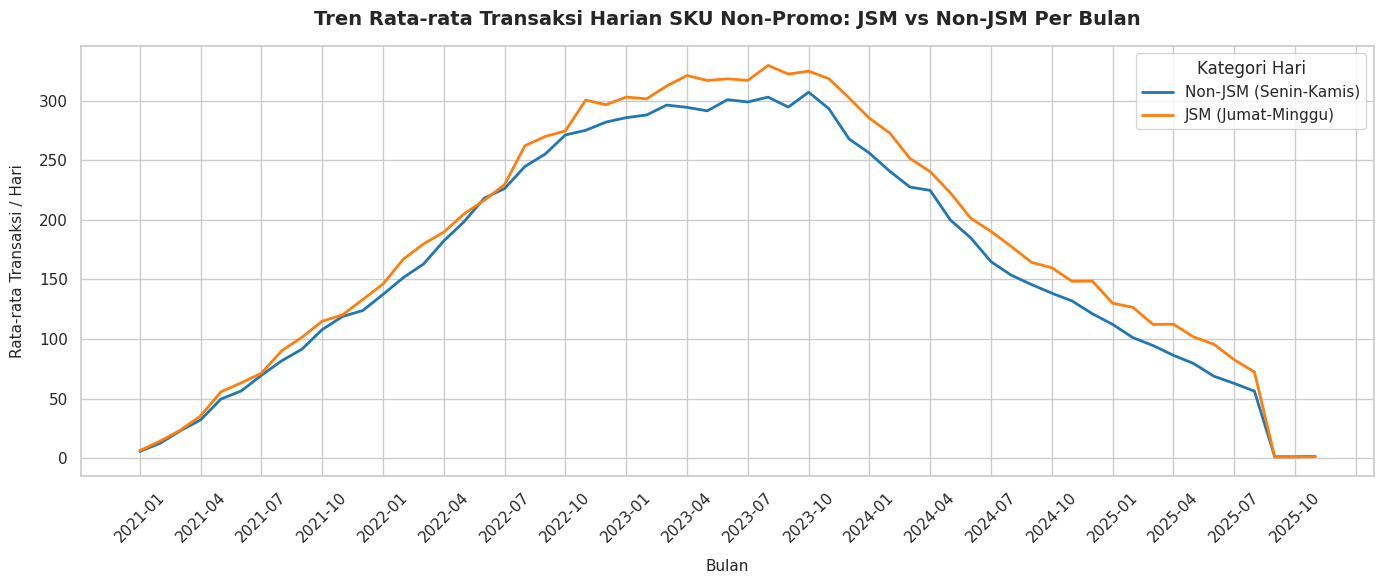

In [ ]:
import matplotlib.ticker as ticker
# 1. Agregasi jumlah transaksi per HARI
daily_trx = df[(df['qty']<=df['batas_wajar_qty'])&(df['is_jsm_promo']== 0)].groupby([
    df['date'].dt.to_period('M').rename('bulan'),
    df['date'].dt.strftime('%Y-%m-%d').rename('tanggal'),
    'is_jsm_day'
])['receipt_id'].nunique().reset_index()

# 2. Hitung rata-rata harian per BULAN untuk masing-masing kelompok
monthly_comparison = daily_trx.groupby(['bulan', 'is_jsm_day'])['receipt_id'].mean().unstack()

# 3. Merapikan nama kolom dan format tampilan
monthly_comparison.columns = ['Rata-rata Harian Non-JSM', 'Rata-rata Harian JSM']
monthly_comparison['Selisih (JSM vs Non-JSM)'] = monthly_comparison['Rata-rata Harian JSM'] - monthly_comparison['Rata-rata Harian Non-JSM']
monthly_comparison['Pertumbuhan (%)'] = (monthly_comparison['Selisih (JSM vs Non-JSM)'] / monthly_comparison['Rata-rata Harian Non-JSM']) * 100

# Tampilkan hasil
# Set style tampilan
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Ubah index 'bulan' ke string
bulan_str = monthly_comparison.index.astype(str)

# Plot Garis (Tanpa Data Label di Setiap Titik)
plt.plot(
    bulan_str,
    monthly_comparison['Rata-rata Harian Non-JSM'],
    linewidth=2,
    label='Non-JSM (Senin-Kamis)',
    color='#1f77b4',
)
plt.plot(
    bulan_str,
    monthly_comparison['Rata-rata Harian JSM'],
    linewidth=2,
    label='JSM (Jumat-Minggu)',
    color='#ff7f0e',
)

# Konfigurasi Judul & Label Sumbu
plt.title(
    'Tren Rata-rata Transaksi Harian SKU Non-Promo: JSM vs Non-JSM Per Bulan',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Bulan', fontsize=11, labelpad=10)
plt.ylabel('Rata-rata Transaksi / Hari', fontsize=11, labelpad=10)

# RAPIKAN SUMBU X: Tampilkan label setiap 3 bulan sekali agar tidak berdesakan
ax = plt.gca()
ax.xaxis.set_major_locator(ticker.MultipleLocator(3))

plt.xticks(rotation=45)
plt.legend(title='Kategori Hari', frameon=True)
plt.tight_layout()

# Tampilkan Grafik
plt.show()

In [ ]:
daily_trx.groupby('is_jsm_day')['receipt_id'].mean()

,receipt_id
is_jsm_day,
False,172.604485
True,188.804082


Secara rata-rata perhari promo jsm berhasil menarik lebih banyak pelanggan dibanding pada hari biasa

### 4.3.2. Apakah Omzet dan Qty produk Non-Promo yang terjual lebih tinggi di hari JSM dibanding hari biasa? (indikator no.2)

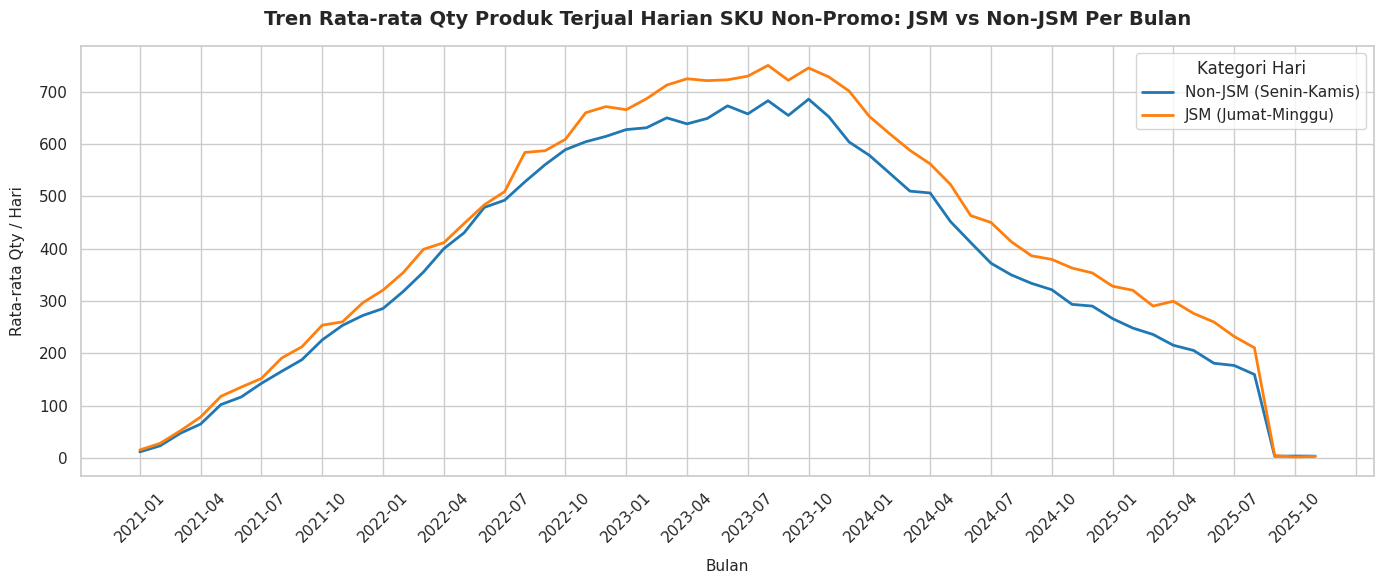

In [ ]:
# 1. Agregasi total QTY per HARI
daily_qty = df[(df['qty']<=df['batas_wajar_qty'])&(df['is_jsm_promo']== 0)].groupby([
    df['date'].dt.to_period('M').rename('bulan'),
    df['date'].dt.strftime('%Y-%m-%d').rename('tanggal'),
    'is_jsm_day'
])['qty'].sum().reset_index()

# 2. Hitung rata-rata QTY harian per BULAN
monthly_qty = daily_qty.groupby(['bulan', 'is_jsm_day'])['qty'].mean().unstack()
monthly_qty.columns = ['Rata-rata Qty Harian Non-JSM', 'Rata-rata Qty Harian JSM']

# 3. Plot Grafik Tren
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

bulan_str = monthly_qty.index.astype(str)

plt.plot(
    bulan_str,
    monthly_qty['Rata-rata Qty Harian Non-JSM'],
    linewidth=2,
    label='Non-JSM (Senin-Kamis)',
    color='#1f77b4',
)
plt.plot(
    bulan_str,
    monthly_qty['Rata-rata Qty Harian JSM'],
    linewidth=2,
    label='JSM (Jumat-Minggu)',
    color='#ff7f0e',
)

# Konfigurasi Judul & Sumbu
plt.title(
    'Tren Rata-rata Qty Produk Terjual Harian SKU Non-Promo: JSM vs Non-JSM Per Bulan',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Bulan', fontsize=11, labelpad=10)
plt.ylabel('Rata-rata Qty / Hari', fontsize=11, labelpad=10)

# Rapikan sumbu X (tampilkan setiap 3 bulan)
ax = plt.gca()
ax.xaxis.set_major_locator(ticker.MultipleLocator(3))

plt.xticks(rotation=45)
plt.legend(title='Kategori Hari', frameon=True)
plt.tight_layout()

plt.show()

In [ ]:
daily_qty.groupby('is_jsm_day')['qty'].mean()

,qty
is_jsm_day,
False,384.859327
True,432.945578


Secara rata-rata perhari, promo jsm berhasil meningkatkan jumlah barang yang dibeli

In [ ]:
# --- ASUMSI NAMA KOLOM ---
kolom_tanggal = 'trx_time'
kolom_struk = 'receipt_id'
kolom_harga = 'total_price'

# 1. MENGGABUNGKAN DATA & MEMBUANG OUTLIER
df_all = df.copy()
df_normal = df_all[df_all['qty'] <= df_all['batas_wajar_qty']].copy()

# 2. MENGATUR PERIODE HARI (Senin-Kamis vs Jumat-Minggu)
df_normal[kolom_tanggal] = pd.to_datetime(df_normal[kolom_tanggal])
df_normal['periode_hari'] = df_normal[kolom_tanggal].dt.dayofweek.apply(
    lambda x: 'Jumat-Minggu (JSM)' if x >= 4 else 'Senin-Kamis (Reguler)'
)

# 3. FILTER MURNI BARANG REGULER (MENGABAIKAN ITEM DISKON JSM)
# Hanya mengambil baris transaksi di mana barang tersebut dibeli dengan harga penuh (tanpa diskon)
df_reguler_saja = df_normal[df_normal['is_jsm_promo'] == 0].copy()

# 4. AGREGASI LEVEL STRUK (Menghitung Total Barang Reguler per Kunjungan)
keranjang_murni = df_reguler_saja.groupby([kolom_struk, 'periode_hari']).agg(
    qty_reguler=('qty', 'sum'),
    revenue_reguler=(kolom_harga, 'sum')
).reset_index()

# Pisahkan dataset berdasarkan periode
basket_wd_murni = keranjang_murni[keranjang_murni['periode_hari'] == 'Senin-Kamis (Reguler)']
basket_we_murni = keranjang_murni[keranjang_murni['periode_hari'] == 'Jumat-Minggu (JSM)']

# --- 5. FUNGSI UJI STATISTIK & CONFIDENCE INTERVAL ---
def uji_halo_effect(data_weekend, data_weekday):
    # Welch's T-Test (Satu Arah)
    t_stat, p_val = stats.ttest_ind(data_weekend, data_weekday, equal_var=False, alternative='greater')

    # Confidence Interval 95%
    n1, n2 = len(data_weekend), len(data_weekday)
    m1, m2 = data_weekend.mean(), data_weekday.mean()
    v1, v2 = data_weekend.var(ddof=1), data_weekday.var(ddof=1)

    diff = m1 - m2
    se = np.sqrt(v1/n1 + v2/n2)
    df = (v1/n1 + v2/n2)**2 / ((v1/n1)**2/(n1-1) + (v2/n2)**2/(n2-1))
    t_crit = stats.t.ppf(0.975, df)

    moe = t_crit * se
    return m1, m2, p_val, diff, (diff - moe), (diff + moe)

# Eksekusi Uji pada Kuantitas dan Omzet Barang Reguler
m1_qty, m2_qty, pval_qty, diff_qty, ci_low_qty, ci_up_qty = uji_halo_effect(
    basket_we_murni['qty_reguler'], basket_wd_murni['qty_reguler']
)

m1_rev, m2_rev, pval_rev, diff_rev, ci_low_rev, ci_up_rev = uji_halo_effect(
    basket_we_murni['revenue_reguler'], basket_wd_murni['revenue_reguler']
)

# --- 6. OUTPUT HASIL ANALISIS ---
print("=== 🛒 PENGUJIAN MURNI 'HALO EFFECT' (CROSS-SELLING) 🛒 ===")
print("Data: Hanya menghitung barang reguler (discount_amount = 0), Outlier dibuang\n")

print("--- A. Pertumbuhan Pembelian Barang Reguler (Qty per Struk) ---")
print(f"Rata-rata Senin-Kamis : {m2_qty:.2f} pcs / struk")
print(f"Rata-rata Jumat-Minggu: {m1_qty:.2f} pcs / struk")
print(f"P-Value (T-Test)      : {pval_qty:.5f}")
if ci_low_qty > 0:
    print(f"Confidence Inter. 95% : 📈 Diestimasi NAIK sebesar {ci_low_qty:.2f} s/d {ci_up_qty:.2f} pcs\n")
else:
    print(f"Confidence Inter. 95% : 📉 Tidak ada kenaikan signifikan (Batas Bawah CI: {ci_low_qty:.2f})\n")

print("--- B. Pertumbuhan Nilai Belanja Barang Reguler (Omzet per Struk) ---")
print(f"Rata-rata Senin-Kamis : Rp {m2_rev:,.0f} / struk")
print(f"Rata-rata Jumat-Minggu: Rp {m1_rev:,.0f} / struk")
print(f"P-Value (T-Test)      : {pval_rev:.5f}")
if ci_low_rev > 0:
    print(f"Confidence Inter. 95% : 📈 Diestimasi NAIK sebesar Rp {ci_low_rev:,.0f} s/d Rp {ci_up_rev:,.0f}\n")
else:
    print(f"Confidence Inter. 95% : 📉 Tidak ada kenaikan signifikan (Batas Bawah CI: Rp {ci_low_rev:,.0f})\n")

# --- 7. KESIMPULAN OTOMATIS ---
print("=== 💡 INSIGHT PAMUNGKAS UNTUK MANAJEMEN ===")
if pval_rev < 0.05 and ci_low_rev > 0:
    print("✅ JSM ADALAH UMPAN YANG SEMPURNA (LOSS-LEADER BERHASIL).")
    print("Meskipun kita tidak menghitung barang diskon, struk pelanggan di akhir pekan secara statistik")
    print("terbukti memiliki nilai barang reguler yang lebih tinggi dibandingkan hari kerja.")
    print("Pelanggan benar-benar terstimulasi untuk merogoh kocek lebih dalam untuk membeli produk bermargin penuh.")
    print("Rekomendasi: Lanjutkan JSM. Subsidi diskon terbayar lunas oleh margin silang (cross-margin).")
else:
    print("🚨 KANIBALISASI FATAL (CHERRY-PICKING).")
    print("Tanpa menghitung barang diskon, keranjang belanja akhir pekan ternyata sama saja atau lebih kecil dari hari kerja.")
    print("Pelanggan B2C terbukti datang HANYA untuk 'memungut' barang promo, lalu langsung ke kasir.")
    print("Rekomendasi: Rombak mekanik promosi. Gunakan syarat 'Beli produk reguler minimal Rp X, baru bisa tebus murah JSM'.")

=== 🛒 PENGUJIAN MURNI 'HALO EFFECT' (CROSS-SELLING) 🛒 ===
Data: Hanya menghitung barang reguler (discount_amount = 0), Outlier dibuang

--- A. Pertumbuhan Pembelian Barang Reguler (Qty per Struk) ---
Rata-rata Senin-Kamis : 2.23 pcs / struk
Rata-rata Jumat-Minggu: 2.29 pcs / struk
P-Value (T-Test)      : 0.00000
Confidence Inter. 95% : 📈 Diestimasi NAIK sebesar 0.05 s/d 0.07 pcs

--- B. Pertumbuhan Nilai Belanja Barang Reguler (Omzet per Struk) ---
Rata-rata Senin-Kamis : Rp 55,074 / struk
Rata-rata Jumat-Minggu: Rp 56,379 / struk
P-Value (T-Test)      : 0.00000
Confidence Inter. 95% : 📈 Diestimasi NAIK sebesar Rp 969 s/d Rp 1,643

=== 💡 INSIGHT PAMUNGKAS UNTUK MANAJEMEN ===
✅ JSM ADALAH UMPAN YANG SEMPURNA (LOSS-LEADER BERHASIL).
Meskipun kita tidak menghitung barang diskon, struk pelanggan di akhir pekan secara statistik
terbukti memiliki nilai barang reguler yang lebih tinggi dibandingkan hari kerja.
Pelanggan benar-benar terstimulasi untuk merogoh kocek lebih dalam untuk membeli pr

# 5. Rekomendasi Pembatasan Qty Pembelian Promo JSM & Dampak Finansial

In [ ]:
low = ci_low_rev * df[(df_all['qty'] <= df_all['batas_wajar_qty']) & (df_normal['is_jsm_promo'] == 0)].groupby([df['date'].dt.month, df['date'].dt.year])['receipt_id'].count().mean()
up = ci_up_rev * df[(df_all['qty'] <= df_all['batas_wajar_qty']) & (df_normal['is_jsm_promo'] == 0)].groupby([df['date'].dt.month, df['date'].dt.year])['receipt_id'].count().mean()

print(f"Diestimasi NAIK sebesar (tanpa pemborong): Rp {low:,.0f} s/d Rp {up:,.0f}\n")

Diestimasi NAIK sebesar (tanpa pemborong): Rp 5,058,034 s/d Rp 8,580,531



In [ ]:
asumsi_budget = total_diskon_jsm - total_diskon_borongan
asumsi_budget

np.float64(730907851.0)

In [ ]:
budget_per_bulan = asumsi_budget/len(df.groupby([df['date'].dt.month, df['date'].dt.year])['date'])
print(f'Diestimasi Budget promo (tanpa pemborong): {budget_per_bulan:,.0f}')

Diestimasi Budget promo (tanpa pemborong): 12,388,269


# 6. Tambahan Tabel Agregat Qty dan Transaksi Promo JSM Lengkap (untuk reference)

## Setting-up

In [ ]:
# ============================================================
# BAGIAN 5 — LANJUTAN ANALISIS: Peta Persebaran, Dampak Finansial & Simulasi Kebijakan
# Prasyarat: `df` (dataset clean) dari cell sebelumnya. Jika belum ada, dibaca dari CSV hasil export.
# ============================================================
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from IPython.display import display, Markdown

# Palet template: putih, hitam, kuning, biru muda, merah, biru tua
WHITE, BLACK, YELLOW, LBLUE, RED, BLUE = "#ffffff", "#000000", "#ffd503", "#dbe9fa", "#ed1c24", "#005aab"
CMAP_BLUE = LinearSegmentedColormap.from_list("w2b", [WHITE, LBLUE, BLUE])
plt.rcParams.update({
    "figure.facecolor": WHITE, "axes.facecolor": WHITE, "savefig.facecolor": WHITE,
    "axes.edgecolor": BLACK, "axes.labelcolor": BLACK, "text.color": BLACK,
    "xtick.color": BLACK, "ytick.color": BLACK, "axes.grid": True, "grid.color": LBLUE,
    "grid.linewidth": 0.9, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10.5, "axes.titleweight": "bold", "axes.titlesize": 12.5, "legend.frameon": False,
})
os.makedirs("figures", exist_ok=True)
def save_fig(fig, name): fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight", facecolor=WHITE)
def rp_jt(x):  return f"{x/1e6:,.0f}"
def rp_m(x):   return f"Rp {x/1e9:,.2f} M"          # M = miliar rupiah

# --- Dataframe analisis (salinan; df asli tidak diubah) ---
try:
    _src = df
except NameError:
    _src = pd.read_csv("alfa_dataset_clean.csv")
dfa = _src.copy()
dfa["date"] = pd.to_datetime(dfa["date"]); dfa["trx_time"] = pd.to_datetime(dfa["trx_time"])
for c in ["is_jsm_promo", "is_jsm_day"]:
    dfa[c] = dfa[c].astype(bool)
dfa["is_member"] = dfa["member_id"].ne("Non Member")

def _iqr_ub(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    return q3 + 1.5 * (q3 - q1)
if "batas_wajar_qty" not in dfa:
    dfa["batas_wajar_qty"] = dfa.groupby("product_name")["qty"].transform(lambda x: _iqr_ub(x.dropna()))

dfa["is_extreme"]     = dfa["qty"] > 24                     # asumsi qty wajar <= 24
dfa["is_outlier_iqr"] = dfa["qty"] > dfa["batas_wajar_qty"]  # asumsi qty wajar = batas atas IQR per produk
dfa["gross"]          = dfa["unit_price"] * dfa["qty"]       # nilai sebelum diskon
# (qty - batas_wajar)/qty x discount_amount  -> bagian diskon yang "melewati batas". Baris tidak outlier = 0 (bukan negatif).
dfa["excess_iqr"] = np.where(dfa["is_outlier_iqr"], dfa["discount_amount"] * (dfa["qty"] - dfa["batas_wajar_qty"]) / dfa["qty"], 0.0)
dfa["excess_24"]  = np.where(dfa["is_extreme"],     dfa["discount_amount"] * (dfa["qty"] - 24) / dfa["qty"], 0.0)
dfa["anomali_qty"] = dfa["qty"] >= 100                      # diduga salah input / sentinel (mis. qty=999); dipakai HANYA di uji sensitivitas

N_DAYS = dfa.groupby("is_jsm_day")["date"].nunique()        # hari kalender: Sen-Kam vs Jum-Min
YEARS  = (dfa["date"].max() - dfa["date"].min()).days / 365.25
PASAR  = "Dekat Pasar/Grosir"
jsm_promo   = dfa[dfa["is_jsm_promo"] & dfa["is_jsm_day"]].copy()
TOTAL_DISK  = jsm_promo["discount_amount"].sum()

print(f"Baris dfa: {len(dfa):,} | struk unik: {dfa['receipt_id'].nunique():,} | periode: {dfa['date'].min().date()} s/d {dfa['date'].max().date()} ({YEARS:.2f} tahun)")
print(f"Hari kalender  Sen-Kam: {N_DAYS[False]:,} | Jum-Min (JSM): {N_DAYS[True]:,}")
print(f"Total diskon JSM (SKU promo x hari JSM): {rp_m(TOTAL_DISK)} | baris: {len(jsm_promo):,}")
print(f"Baris dengan qty >= 100 (diduga anomali input): {dfa['anomali_qty'].sum():,} ({dfa['anomali_qty'].mean()*100:.3f}%), qty=999: {(dfa['qty']==999).sum():,}")

Baris dfa: 431,012 | struk unik: 431,012 | periode: 2021-01-07 s/d 2025-11-15 (4.85 tahun)
Hari kalender  Sen-Kam: 1,000 | Jum-Min (JSM): 755
Total diskon JSM (SKU promo x hari JSM): Rp 8.48 M | baris: 54,057
Baris dengan qty >= 100 (diduga anomali input): 310 (0.072%), qty=999: 157


## Visualization - Tabel Agregat Persebaran Seluruh Transaksi/Receipt

Kombinasi terisi: 14 dari 16 | total struk di tabel = 431,012 = len(dfa) 431,012


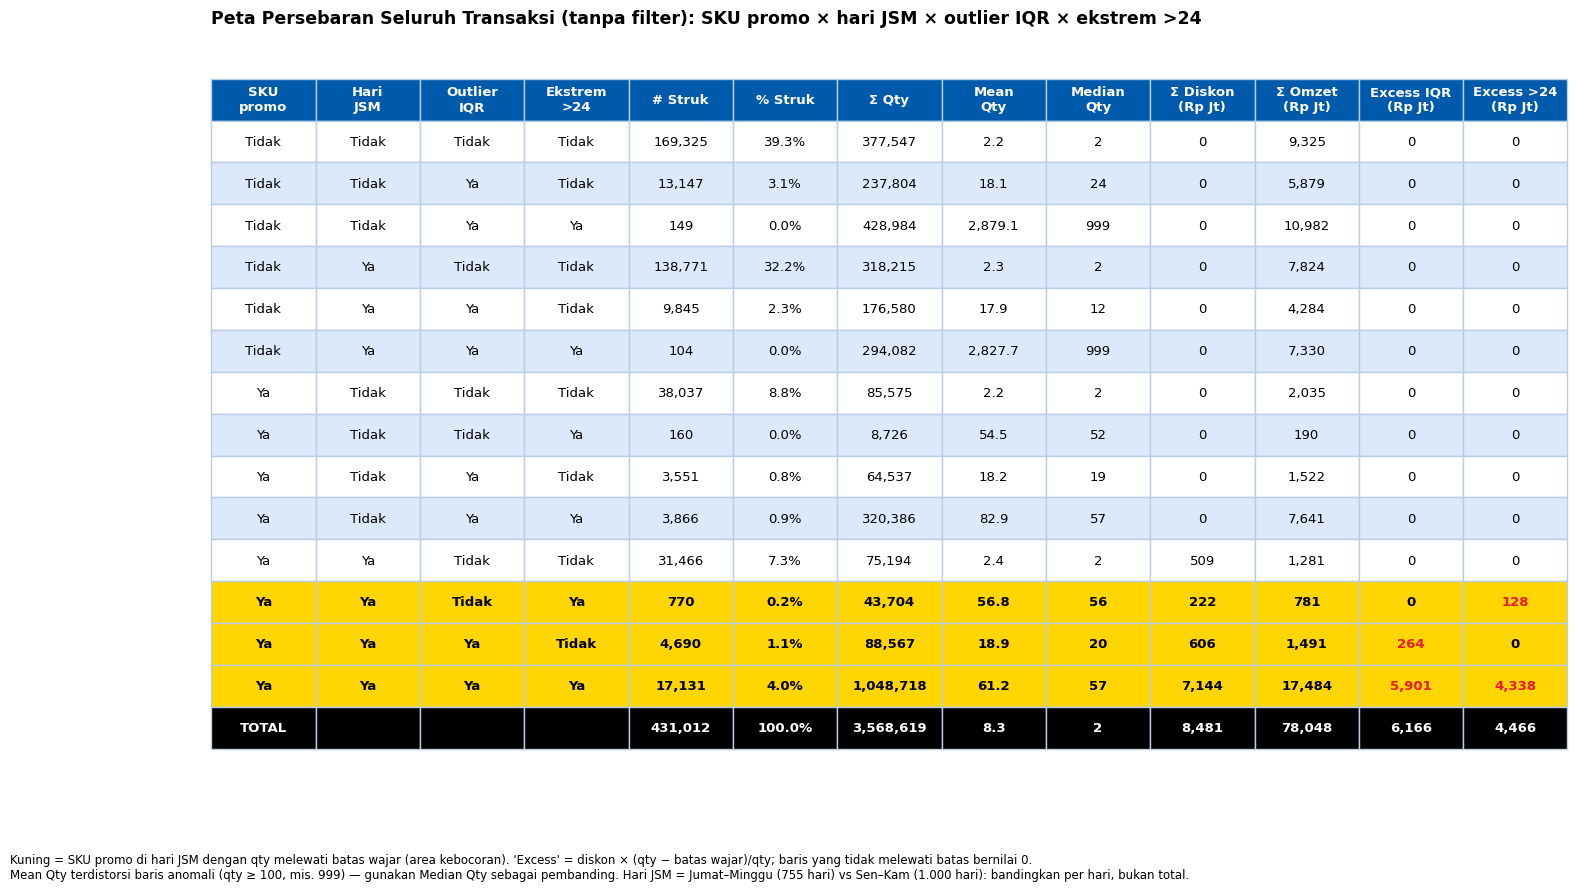

In [ ]:
# ---------- 5.1  PETA PERSEBARAN: agregat SELURUH dataframe (tanpa filter apa pun) ----------
def save_fig(fig, name): fig.savefig(f"{name}.png", dpi=200, bbox_inches="tight", facecolor=WHITE)

FLAGS = ["is_jsm_promo", "is_jsm_day", "is_outlier_iqr", "is_extreme"]
AGG = dict(struk=("receipt_id", "nunique"), qty_sum=("qty", "sum"), qty_mean=("qty", "mean"), qty_median=("qty", "median"),
           diskon=("discount_amount", "sum"), omzet=("total_price", "sum"),
           excess_iqr=("excess_iqr", "sum"), excess_24=("excess_24", "sum"))
peta = dfa.groupby(FLAGS).agg(**AGG).reset_index()
tot = pd.Series(dict(struk=dfa["receipt_id"].nunique(), qty_sum=dfa["qty"].sum(), qty_mean=dfa["qty"].mean(), qty_median=dfa["qty"].median(),
                     diskon=dfa["discount_amount"].sum(), omzet=dfa["total_price"].sum(),
                     excess_iqr=dfa["excess_iqr"].sum(), excess_24=dfa["excess_24"].sum()))
# Sanity: tabel mencakup seluruh dataframe (tidak ada baris yang terbuang)
assert peta["struk"].sum() == len(dfa) and np.isclose(peta["omzet"].sum(), dfa["total_price"].sum())
print(f"Kombinasi terisi: {len(peta)} dari 16 | total struk di tabel = {peta['struk'].sum():,} = len(dfa) {len(dfa):,}")

ya = lambda v: "Ya" if v else "Tidak"
HDR = ["SKU\npromo", "Hari\nJSM", "Outlier\nIQR", "Ekstrem\n>24", "# Struk", "% Struk", "Σ Qty", "Mean\nQty", "Median\nQty",
       "Σ Diskon\n(Rp Jt)", "Σ Omzet\n(Rp Jt)", "Excess IQR\n(Rp Jt)", "Excess >24\n(Rp Jt)"]
def baris(r, t):
    return [f"{r.struk:,.0f}", f"{r.struk/t.struk*100:.1f}%", f"{r.qty_sum:,.0f}", f"{r.qty_mean:,.1f}", f"{r.qty_median:,.0f}",
            rp_jt(r.diskon), rp_jt(r.omzet), rp_jt(r.excess_iqr), rp_jt(r.excess_24)]
cells = [[ya(r.is_jsm_promo), ya(r.is_jsm_day), ya(r.is_outlier_iqr), ya(r.is_extreme)] + baris(r, tot) for r in peta.itertuples()]
cells.append(["TOTAL", "", "", ""] + baris(tot, tot))

fig, ax = plt.subplots(figsize=(17.5, 0.5 * len(cells) + 1.2)); ax.axis("off")
tb = ax.table(cellText=cells, colLabels=HDR, bbox=[0, 0, 1, 1], cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(9.5); pass
for (i, j), c in tb.get_celld().items():
    c.set_edgecolor("#b9cde6")
    if i == 0:
        c.set_facecolor(BLUE); c.set_text_props(color=WHITE, weight="bold")
    elif i == len(cells):
        c.set_facecolor(BLACK); c.set_text_props(color=WHITE, weight="bold")
    else:
        r = peta.iloc[i - 1]
        c.set_facecolor(LBLUE if i % 2 == 0 else WHITE)
        if r.is_jsm_promo and r.is_jsm_day and (r.is_outlier_iqr or r.is_extreme):
            c.set_facecolor(YELLOW); c.set_text_props(weight="bold")
        if j in (11, 12) and float(cells[i - 1][j].replace(",", "")) > 0:
            c.set_text_props(color=RED, weight="bold")
ax.set_title("Peta Persebaran Seluruh Transaksi (tanpa filter): SKU promo × hari JSM × outlier IQR × ekstrem >24", loc="left", pad=40)
fig.text(0.01, -0.01, "Kuning = SKU promo di hari JSM dengan qty melewati batas wajar (area kebocoran). 'Excess' = diskon × (qty − batas wajar)/qty; baris yang tidak melewati batas bernilai 0.\n"
                    "Mean Qty terdistorsi baris anomali (qty ≥ 100, mis. 999) — gunakan Median Qty sebagai pembanding. Hari JSM = Jumat–Minggu (755 hari) vs Sen–Kam (1.000 hari): bandingkan per hari, bukan total.",
         fontsize=8.5, va="top")
save_fig(fig, "01_peta_persebaran_tabel"); plt.show()

# 5. Summary of Findings

## 5.1 Business Insights
1. **Keberhasilan Strategi *Loss Leader* & *Halo Effect*:**
   - Melalui pengujian statistik (*Welch's T-Test* & *Cohen's d*) pada transaksi normal tanpa diskon (`is_jsm_promo == 0`), terbukti bahwa Promo JSM sukses berfungsi sebagai pemancing trafik. Pelanggan B2C terbukti meningkatkan pembelian produk reguler bermargin penuh saat akhir pekan.
2. **Lonjakan Pembelian Anomali (*Promo Hunters / Resellers*):**
   - Hasil *Two-Proportion Z-Test* membuktikan adanya lonjakan transaksi di atas batas wajar konsumsi rumah tangga (\\(Q3 + 1.5 \times IQR\\)), meningkat dari **8,14% pada hari biasa** menjadi **39,92% saat periode JSM** (\\(p\text{-value} = 0.00\\)).
3. **Eksploitasi Fasilitas Keanggotaan (*Super Member*):**
   - Sebanyak **72,0% dari total transaksi borongan JSM** dilakukan menggunakan kartu *Member*. Hal ini mengindikasikan bahwa *reseller* beroperasi secara teredukasi dari dalam sistem dan memicu beban ganda (*double margin hit*: diskon harga + poin loyalti).
4. **Episentrum Kebocoran Stok (*Geotargeting Analysis*):**
   - Sebanyak **90,3% transaksi borongan JSM** (19.763 dari 21.886 struk anomali) terpusat pada gerai bertipe **"Dekat Pasar/Grosir"**.
   - Sebaliknya, proporsi borongan di gerai tipe **"Residential/Perumahan"** justru menyusut di bawah 10%, membuktikan bahwa stok subsidi yang seharusnya dinikmati ibu rumah tangga tersedot habis oleh pedagang pasar.

## 5.2 Actionable Recommendations
1. **Implementasi *Dynamic Hard Limit* pada Kasir POS:**
   - Terapkan pembatasan kuantitas maksimal otomatis (*max qty per receipt/member*) pada sistem kasir POS dan aplikasi Alfagift khusus untuk SKU promo rawan borongan (misal: Minyak Goreng, Indomie, Aqua) berdasarkan parameter \\(Q3 + 1.5 \times IQR\\).
2. **Penerapan Kebijakan *Geotargeting Restrictions*:**
   - Terapkan aturan batas kuantitas ketat difokuskan pada klaster gerai bertipe **"Dekat Pasar/Grosir"**, sementara gerai tipe **"Residential/Perumahan"** tetap diberikan kuota lebih fleksibel agar kenyamanan belanja pelanggan B2C tidak terganggu.
3. **Restrukturisasi Mekanik Promosi (*Cross-Selling Requirement*):**
   - Ubah skema diskon langsung menjadi promosi bersyarat, misalnya: *"Harga Diskon JSM Minyak Goreng berlaku jika disertai pembelian non promo minimal Rp50.000"* untuk menyaring *reseller* murni sekaligus mengamankan margin silang.
4. **Audit *Super Member* & Pengawasan Internal:**
   - Lakukan pemantauan dan audit operasional untuk mengantisipasi praktik "tembak struk" oleh oknum kasir di area pasar.